# From HCD absorbers to the public likelihood: a tutorial for `hcd_priya`

**PROVISIONAL (PI to refine).** This notebook has three parts.

1. **Scientific motivation.** The Lyman-alpha forest and the high-column-density (HCD) absorbers on the same
   sightlines: Lyman limit systems (LLS), sub-damped and damped Lyman-alpha absorbers (subDLAs, DLAs).
2. **The emulator.** What the published model `hcd_priya` 1.0.0 returns: the flux power spectrum (P1D) of four
   classes of sightline, the incidence of the absorbers, and a mixture of the classes.
3. **The public likelihood and the mock-recovery example.** The package's Gaussian likelihood on the mock of the
   repository's example, at the mock's truth, and the stored result of that example redrawn. Nothing is fitted.

**To run it:** `pip install "hcd-priya[tutorials]"` in Python 3.11 or later, then open this file with Jupyter. The
trained model comes with the package. The few stored files the notebook reads, and the released scripts it runs,
are found in a clone of the repository or downloaded once, each checked against its sha256 (next cell).

In [1]:
import json
import warnings

import matplotlib.pyplot as plt
import numpy as np

import hcd_analysis
import hcd_analysis.predictor as hp

plt.rcParams.update({"font.size": 12, "axes.titlesize": 12, "axes.labelsize": 12, "legend.fontsize": 10,
                     "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3})
CLASS_COLOURS = {"clean": "#4d4d4d", "LLS": "#1f77b4", "subDLA": "#ff7f0e", "DLA": "#d62728"}

print("hcd_analysis", hcd_analysis.__version__)

hcd_analysis 1.0.0


In [2]:
# The stored files of this tutorial. Each is named by its path in the repository (a file of the GitHub release by
# its file name) and pinned by its sha256. Every URL is immutable: the tag v1.0.0, a file of the release v1.0.0,
# or one commit.
import hashlib
import os
import pathlib
import tempfile
import urllib.request

ASSETS = {
    "docs/figures/data/ho21/cddf_z225.txt": {
        "sha256": "feaffb7b88215e767ca53a41fb3f00b65c90aaf27745c28720b32976a9168a63",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/ho21/cddf_z225.txt",
    },
    "docs/figures/data/ho21/cddf_z253.txt": {
        "sha256": "62e93a1e1977b3d78b9f56475bd4390c1eee7eaf371986ca5ece2db338bb7cc7",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/ho21/cddf_z253.txt",
    },
    "docs/figures/data/ho21/cddf_z34.txt": {
        "sha256": "f21dca06cd5974a08de13632ef74109f5b78afc2921f86ec9b3c6cf9f838ad3a",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/ho21/cddf_z34.txt",
    },
    "docs/figures/data/ho21/dndx_all.txt": {
        "sha256": "fb4d86151b34240902dbd6e63914e7c98dbb367fb6880a0e6871c849345ca81c",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/ho21/dndx_all.txt",
    },
    "docs/figures/data/lls_incidence/lls_lz_literature.dat": {
        "sha256": "c7fd68c9effd2f0151fa5293ca57214a106c31e1e4611d63a6442b2b2ff47ae1",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/lls_incidence/lls_lz_literature.dat",
    },
    "docs/figures/data/lls_subdla/zafar_2013.txt": {
        "sha256": "f592ecfd74bb423eae15d9bf40c7aca3e3da61ee7bbc1dab9510e6edca4767bd",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/lls_subdla/zafar_2013.txt",
    },
    "docs/figures/data/lls_subdla/omeara2007_fn_all19p0.dat": {
        "sha256": "695fd5e611368249b17b8de0ccf42aab8ee5c74c68f0750f7997c6c3d81f70bc",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/lls_subdla/omeara2007_fn_all19p0.dat",
    },
    "docs/figures/data/lls_subdla/prochaska2010_lls_region.dat": {
        "sha256": "9afad095522ac3d25ea1b615df91b806758ab50b42268dd6fea37412d689b39b",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/lls_subdla/prochaska2010_lls_region.dat",
    },
    "docs/figures/data/class_ratio_ranges_z3p0_lf60.csv": {
        "sha256": "0f79f1e5260df432fbe3b69b32dd4d4ebca248e95f789b11c40be549ef926f05",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/class_ratio_ranges_z3p0_lf60.csv",
    },
    "hcd_priya_example_download.tar.gz": {
        "sha256": "27bd0f96c88ae195175351bbf05468188b8fdf745c99bac9e54bebf571e31d7a",
        "url": "https://github.com/jibanCat/hcd_priya/releases/download/v1.0.0/hcd_priya_example_download.tar.gz",
    },
    "notebooks/tutorial/assets/figures/joss_architecture.png": {
        "sha256": "47302de8ce8d49e523312e1a67590ce8f0829cfa3d728e8cb304723bd3f6c68d",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/7caaeb52c9ecffd9c6472a8231533389c990cc86/notebooks/tutorial/assets/figures/joss_architecture.png",
    },
    "examples/mock_recovery.py": {
        "sha256": "6bd6f300caf6d2d82edd5bb5bb745523c6c9ec8f08612902aa23a812ab47093a",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/examples/mock_recovery.py",
    },
    "scripts/figures/figures_common.py": {
        "sha256": "aa1f2bc4320c3fb78ea820a355193b832b1f3454bdae51428cec8ad867a2200e",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/scripts/figures/figures_common.py",
    },
    "scripts/figures/fig_dndx_vs_ho21.py": {
        "sha256": "66301416141d6340cb20b45e58a83f089e84e2e6dd7a14c87511396eb59001e0",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/scripts/figures/fig_dndx_vs_ho21.py",
    },
    "scripts/figures/fig_cddf_vs_ho21.py": {
        "sha256": "4884bfe4cf55155882516b625f319c65d6aac46f2a09b7df02a47fc376777e65",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/scripts/figures/fig_cddf_vs_ho21.py",
    },
    "scripts/figures/fig_class_ratio_vs_rogers18.py": {
        "sha256": "5825e6935ff46561190b070deb72a11a39b439ee127616648aa63148ade7c3f6",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/scripts/figures/fig_class_ratio_vs_rogers18.py",
    },
    "docs/figures/data/priya_lf_design_60.csv": {
        "sha256": "a47f23bfce73b3d765206cef5b116cf42b3705c9a0df85a5e665cda185255d42",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/priya_lf_design_60.csv",
    },
    "docs/figures/data/SHA256SUMS": {
        "sha256": "2afe737238bbc832b1da5606cc05b8095fe236a9b5164a33add1556e43330d84",
        "url": "https://raw.githubusercontent.com/jibanCat/hcd_priya/v1.0.0/docs/figures/data/SHA256SUMS",
    },
}

# Inside a clone of the repository the files are on disk already. A local file is used when, and only when, its
# sha256 is the pinned one, so the notebook reads the same bytes inside a clone and outside one. This notebook's
# folder is two levels below the top of a clone.
LOCAL_ROOTS = (pathlib.Path.cwd(), pathlib.Path.cwd().parent.parent)


def sha256_of(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1 << 20), b""):
            digest.update(block)
    return digest.hexdigest()


def tutorial_cache():
    # the folder downloaded files are kept in
    return pathlib.Path(os.environ.get("HCD_PRIYA_TUTORIAL_CACHE", "~/.cache/hcd_priya_tutorial")).expanduser()


def tutorial_file(relpath):
    # The path of a stored file of the tutorial, with the pinned sha256: a local copy in a clone, a copy
    # downloaded earlier, or a new download into the cache folder (the environment variable
    # HCD_PRIYA_TUTORIAL_CACHE, default ~/.cache/hcd_priya_tutorial).
    if relpath not in ASSETS:
        raise RuntimeError(f"{relpath} is not a stored file of this tutorial (ASSETS names {len(ASSETS)} files)")
    pinned, url = ASSETS[relpath]["sha256"], ASSETS[relpath]["url"]
    for root in LOCAL_ROOTS:
        local = pathlib.Path(root) / relpath
        if local.is_file() and sha256_of(local) == pinned:
            return local
    cache = tutorial_cache()
    target = cache / relpath
    if target.is_file() and sha256_of(target) == pinned:
        return target
    target.parent.mkdir(parents=True, exist_ok=True)
    # written under a temporary name and renamed only after the digest is checked: no partial file is left
    handle, partial = tempfile.mkstemp(dir=target.parent, prefix=target.name + ".", suffix=".part")
    digest = hashlib.sha256()
    try:
        try:
            with os.fdopen(handle, "wb") as out, urllib.request.urlopen(url, timeout=120) as response:
                for block in iter(lambda: response.read(1 << 20), b""):
                    out.write(block)
                    digest.update(block)
        except Exception as exc:
            raise RuntimeError(
                f"could not download the tutorial file {relpath} from {url} into the cache folder {cache}: {exc}"
            ) from exc
        if digest.hexdigest() != pinned:
            raise RuntimeError(
                f"the tutorial file {relpath} downloaded from {url} has sha256 {digest.hexdigest()}, "
                f"not the pinned {pinned}: it is refused, and nothing is kept in {cache}"
            )
        os.replace(partial, target)
    finally:
        if os.path.exists(partial):
            os.remove(partial)
    return target


print(len(ASSETS), "stored files are pinned by sha256")

18 stored files are pinned by sha256


## Part I. Scientific motivation

**PROVISIONAL (PI to refine).**

**Fig. 1.** PLACEHOLDER: the image from the Leinweber talk (the PI supplies the file and its terms).

**PROVISIONAL (PI to refine).** The figure is to show one quasar sightline: the Lyman-alpha forest, and the
absorbers of high column density on the same sightline, a Lyman limit system (LLS), a sub-damped and a damped
Lyman-alpha absorber (subDLA, DLA) with their damping wings.

### Three classes of absorber

**PROVISIONAL (PI to refine).** The package sorts absorbers by their neutral hydrogen column density $N_\mathrm{HI}$
into three classes, LLS, subDLA and DLA. The next cell prints the edges the package uses and draws the column
density distribution $f(N_\mathrm{HI})$ of published measurements across the three classes. A sightline belongs to
the class of its strongest absorber; a sightline with no such absorber is called clean.

LLS:    10^17.2 <= N_HI < 10^19.0 cm^-2
subDLA: 10^19.0 <= N_HI < 10^20.3 cm^-2
DLA:    N_HI >= 10^20.3 cm^-2


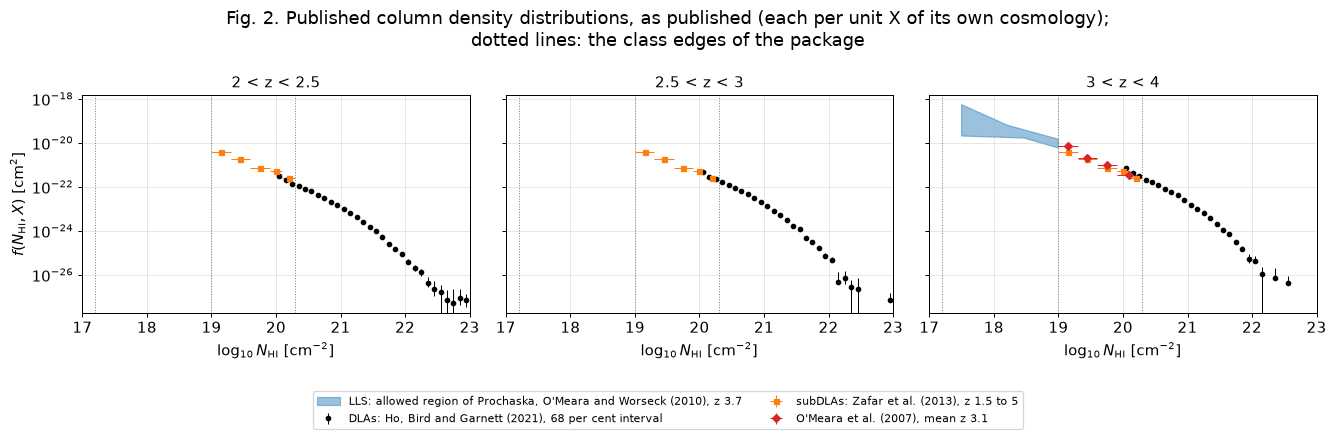

the points drawn run from log10 N_HI = 17.50 to 22.95
and f from 5.24e-19 down to 5.28e-28 cm^2: 9.0 decades of f
the forest lies below the lowest class edge, log10 N_HI = 17.2, and is not drawn


In [3]:
# Fig. 2. The column density distribution f(N_HI) from published measurements, from LLS to DLAs.
import hcd_analysis.catalog as catalog

EDGES = (catalog.LOG_NHI_LLS_MIN, catalog.LOG_NHI_SUBDLA_MIN, catalog.LOG_NHI_DLA_MIN)
print(f"LLS:    10^{EDGES[0]} <= N_HI < 10^{EDGES[1]} cm^-2")
print(f"subDLA: 10^{EDGES[1]} <= N_HI < 10^{EDGES[2]} cm^-2")
print(f"DLA:    N_HI >= 10^{EDGES[2]} cm^-2")

DATA = "docs/figures/data/"
CDDF_PANELS = (
    ("2 < z < 2.5", "ho21/cddf_z225.txt"),
    ("2.5 < z < 3", "ho21/cddf_z253.txt"),
    ("3 < z < 4", "ho21/cddf_z34.txt"),
)


def read_ho21_cddf(path):
    # six rows: log10 N_HI of the bin centre, f, the two limits of the 68 per cent interval, those of the 95 per cent
    # interval (not drawn); bins with f = 0 are left out
    table = np.loadtxt(path)
    keep = table[1] > 0
    return table[0][keep], table[1][keep], table[2][keep], table[3][keep]


# Zafar et al. (2013): log10 N_HI, the half-width of the bin, log10 f, its upper and its lower error in dex
z13_logn, z13_half, z13_logf, z13_up, z13_down = np.loadtxt(tutorial_file(DATA + "lls_subdla/zafar_2013.txt"), ndmin=2).T
# O'Meara et al. (2007), all log10: N_HI, f, the two edges of the bin, the two limits of f
o07_logn, o07_logf, o07_lo_n, o07_hi_n, o07_lo_f, o07_hi_f = np.loadtxt(
    tutorial_file(DATA + "lls_subdla/omeara2007_fn_all19p0.dat"), ndmin=2
).T
# Prochaska, O'Meara and Worseck (2010): the corners of the allowed region, log10 N_HI and log10 f
p10 = np.loadtxt(tutorial_file(DATA + "lls_subdla/prochaska2010_lls_region.dat"), ndmin=2)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
drawn_logn, drawn_f = [], []
for ax, (title, name) in zip(axes, CDDF_PANELS):
    logn, f, f_lo, f_hi = read_ho21_cddf(tutorial_file(DATA + name))
    ax.errorbar(logn, f, yerr=[f - f_lo, f_hi - f], fmt="o", ms=3.5, color="black", elinewidth=0.8,
                label="DLAs: Ho, Bird and Garnett (2021), 68 per cent interval")
    z13_f = 10.0**z13_logf
    ax.errorbar(z13_logn, z13_f, xerr=z13_half, yerr=[z13_f - 10.0 ** (z13_logf - z13_down), 10.0 ** (z13_logf + z13_up) - z13_f],
                fmt="s", ms=4, color=CLASS_COLOURS["subDLA"], elinewidth=0.8, label="subDLAs: Zafar et al. (2013), z 1.5 to 5")
    drawn_logn += [logn, z13_logn]
    drawn_f += [f, z13_f]
    if title == "3 < z < 4":
        o07_f = 10.0**o07_logf
        ax.errorbar(o07_logn, o07_f, xerr=[o07_logn - o07_lo_n, o07_hi_n - o07_logn],
                    yerr=[o07_f - 10.0**o07_lo_f, 10.0**o07_hi_f - o07_f], fmt="D", ms=4, color=CLASS_COLOURS["DLA"],
                    elinewidth=0.8, label="O'Meara et al. (2007), mean z 3.1")
        ax.fill(p10[:, 0], 10.0 ** p10[:, 1], facecolor=CLASS_COLOURS["LLS"], edgecolor=CLASS_COLOURS["LLS"], alpha=0.45, lw=1.0,
                label="LLS: allowed region of Prochaska, O'Meara and Worseck (2010), z 3.7")
        drawn_logn += [o07_logn, p10[:, 0]]
        drawn_f += [o07_f, 10.0 ** p10[:, 1]]
    for edge in EDGES:
        ax.axvline(edge, color="grey", lw=0.8, ls=":")
    ax.set_yscale("log")
    ax.set_xlim(17.0, 23.0)
    ax.set_xlabel(r"$\log_{10} N_\mathrm{HI}$ [cm$^{-2}$]")
    ax.set_title(title)
axes[0].set_ylabel(r"$f(N_\mathrm{HI}, X)$ [cm$^2$]")
fig.legend(*axes[2].get_legend_handles_labels(), loc="lower center", ncol=2, fontsize=9)
fig.suptitle("Fig. 2. Published column density distributions, as published (each per unit X of its own cosmology);\n"
             "dotted lines: the class edges of the package")
fig.tight_layout(rect=(0, 0.13, 1, 1))
plt.show()

drawn_logn, drawn_f = np.concatenate(drawn_logn), np.concatenate(drawn_f)
print(f"the points drawn run from log10 N_HI = {drawn_logn.min():.2f} to {drawn_logn.max():.2f}")
print(f"and f from {drawn_f.max():.2e} down to {drawn_f.min():.2e} cm^2: {np.log10(drawn_f.max() / drawn_f.min()):.1f} decades of f")
print(f"the forest lies below the lowest class edge, log10 N_HI = {EDGES[0]}, and is not drawn")

### Why the forest and the strong absorbers are usually treated apart

**PROVISIONAL (PI to refine).**

- *In observations.* DLAs are found one by one in the spectra and are masked, or their damping wings are fitted.
  LLS are not identified one by one at the resolution of a survey spectrum.
- *In simulations.* The strong absorbers depend on self-shielding and on resolution, and emulators of the forest
  are trained on spectra with the strong absorbers removed.

The two treatments meet in the one-dimensional flux power spectrum (P1D), which is measured on the spectra as
they are.

### What is left in the P1D

**PROVISIONAL (PI to refine). HCD contamination is not negligible for small-scale Lyman-alpha cosmology.**

PLACEHOLDER: the statements of Ho et al. (2026) and of the DESI DR1 analysis (Chaves-Montero et al. 2026) on the
absorbers that remain in a measured P1D and on the scales they affect, quoted with their references. Each
sentence is to be checked against its paper before it is written here.

References to be quoted: Ho et al., JCAP 2026 (07) 094; Chaves-Montero et al., JCAP 2026 (06) 040; the DESI DR1
measurements of the P1D, Karacayli et al. (2025) and Ravoux et al. (2025).

## Part II. The emulator

**PROVISIONAL (PI to refine).** The published model was trained on the PRIYA suite of hydrodynamical simulations.
Given nine cosmological and astrophysical parameters, a redshift and a mean flux, it returns the P1D of four
classes of sightline (clean, LLS, subDLA, DLA), the incidence of the three classes of absorber, and the column
density distribution. The next cell loads it and prints what identifies it.

In [4]:
emu = hp.load_published()  # the trained LF+MF model, from the installed package hcd-priya-models

release = emu.provenance["release"]
print("model release:", release["release_version"], "| format:", release["format"])
print("sha256 of its release.json:", release["release_sha256"])

# The point used in this notebook: the midpoint of the range each parameter was trained on. It is a point to try
# the model at: not a fiducial cosmology, not a best fit and not a simulation.
PARAMS = {
    "ns": 0.925,  # slope of the primordial power spectrum at k = 0.78 / Mpc
    "Ap": 1.9e-9,  # its amplitude at the same wavenumber
    "herei": 4.0,  # redshift at which helium reionization starts
    "heref": 2.7,  # redshift at which helium reionization ends
    "alphaq": 2.15,  # quasar spectral index, which sets the heating of helium reionization
    "hub": 0.70,  # dimensionless Hubble parameter h
    "omegamh2": 0.143,  # Omega_m h^2
    "hireionz": 7.25,  # redshift of hydrogen reionization
    "bhfeedback": 0.05,  # black-hole feedback strength
}
print()
print(f"{'parameter':11s} {'trained from':>13s} {'to':>10s} {'used here':>10s}")
for name, (low, high) in zip(hp.PARAM_NAMES, hp.PARAM_LIMITS):
    print(f"{name:11s} {low:13.4g} {high:10.4g} {PARAMS[name]:10.4g}")

# The mean flux is PRIYA's model: tau_eff(z) = tau0_amp ((1 + z) / (1 + z_pivot))**dtau0 times the fit of Kim et
# al. (2007). The model records the range of tau0_amp it was trained on with its training data:
TAU0_AMP_RANGE = tuple(emu.provenance["lineage"]["cache"]["settings"]["alpha_range"])
print(f"{'tau0_amp':11s} {TAU0_AMP_RANGE[0]:13.4g} {TAU0_AMP_RANGE[1]:10.4g} {1.0:10.4g}   (dtau0 = 0 here)")

model release: 1.0.0 | format: hcd_priya.release/1
sha256 of its release.json: c81c33ce65455098620a6e7e54e95bc87f10b06ac10970082ffbc9c6fe5470ad

parameter    trained from         to  used here
ns                    0.8       1.05      0.925
Ap                1.2e-09    2.6e-09    1.9e-09
herei                 3.5        4.5          4
heref                 2.2        3.2        2.7
alphaq                1.3          3       2.15
hub                  0.65       0.75        0.7
omegamh2             0.14      0.146      0.143
hireionz              6.5          8       7.25
bhfeedback           0.03       0.07       0.05
tau0_amp           0.6556      1.331          1   (dtau0 = 0 here)


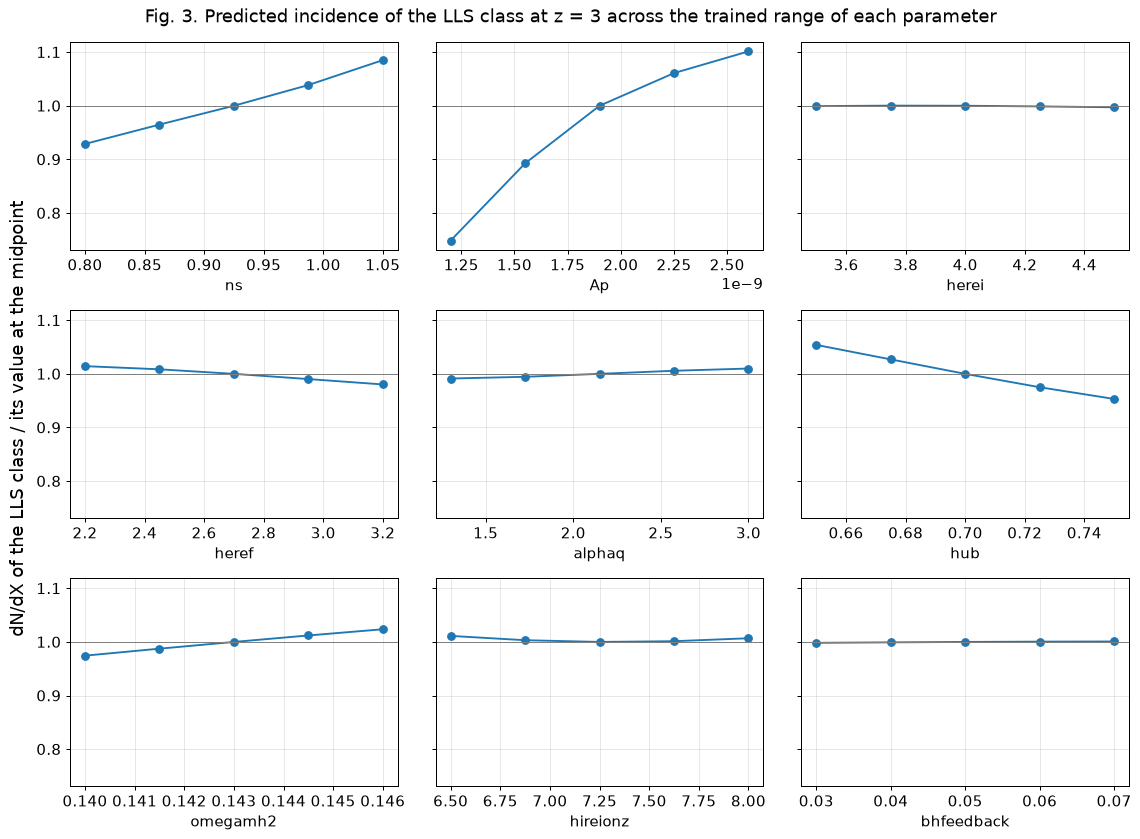

at the midpoint: dN/dX of the LLS class = 0.4337
The change of the predicted LLS incidence across the trained range of each parameter, largest first
(the largest of the five values over the smallest; the value at the low and at the high end over the midpoint):
  Ap          x 1.471   low end 0.749, high end 1.101
  ns          x 1.168   low end 0.929, high end 1.085   flags set along the way: ns_ridge
  hub         x 1.106   low end 1.054, high end 0.953
  omegamh2    x 1.051   low end 0.974, high end 1.024
  heref       x 1.035   low end 1.014, high end 0.980   flags set along the way: outside_sampling_box
  alphaq      x 1.019   low end 0.991, high end 1.010   flags set along the way: outside_sampling_box
  hireionz    x 1.011   low end 1.011, high end 1.007
  herei       x 1.003   low end 0.999, high end 0.997   flags set along the way: outside_sampling_box
  bhfeedback  x 1.002   low end 0.998, high end 1.001


In [5]:
# Fig. 3. The predicted incidence of the LLS class at z = 3 while one parameter at a time crosses the range it was
# trained on (five values; the other eight at the midpoint, the mean flux fixed).
Z0 = 3.0
I_LLS = hp.HCD_CLASSES.index("LLS")
mid = emu.predict(PARAMS, z=Z0, tau0_amp=1.0, dtau0=0.0)
mid_flags = {name for name, value in mid.flags.items() if value is True}

response, new_flags = {}, {}
for name, (low, high) in zip(hp.PARAM_NAMES, hp.PARAM_LIMITS):
    values = np.linspace(low, high, 5)
    rows = [emu.predict(dict(PARAMS, **{name: value}), z=Z0, tau0_amp=1.0, dtau0=0.0) for value in values]
    response[name] = (values, np.array([row.dndx[I_LLS] for row in rows]) / mid.dndx[I_LLS])
    new_flags[name] = sorted({f for row in rows for f, value in row.flags.items() if value is True} - mid_flags)

fig, axes = plt.subplots(3, 3, figsize=(13, 9.5), sharey=True)
for ax, (name, (values, lls)) in zip(axes.ravel(), response.items()):
    ax.plot(values, lls, "o-", color=CLASS_COLOURS["LLS"])
    ax.axhline(1.0, color="grey", lw=0.8)
    ax.set_xlabel(name)
fig.supylabel("dN/dX of the LLS class / its value at the midpoint")
fig.suptitle("Fig. 3. Predicted incidence of the LLS class at z = 3 across the trained range of each parameter")
fig.tight_layout()
plt.show()

print(f"at the midpoint: dN/dX of the LLS class = {mid.dndx[I_LLS]:.4f}")
print("The change of the predicted LLS incidence across the trained range of each parameter, largest first")
print("(the largest of the five values over the smallest; the value at the low and at the high end over the midpoint):")
RANKING = sorted(response, key=lambda name: -(response[name][1].max() / response[name][1].min()))
for name in RANKING:
    values, lls = response[name]
    note = f"   flags set along the way: {', '.join(new_flags[name])}" if new_flags[name] else ""
    print(f"  {name:11s} x {lls.max() / lls.min():.3f}   low end {lls[0]:.3f}, high end {lls[-1]:.3f}{note}")

**PROVISIONAL (PI to refine).** Reading Fig. 3: the printed list ranks the nine parameters by how much the
predicted LLS incidence changes across the range each was trained on. The absorber population is itself a
prediction of the model, and it depends on cosmological and on astrophysical parameters; which of the two kinds
matters more is to be read from the list above and written here.

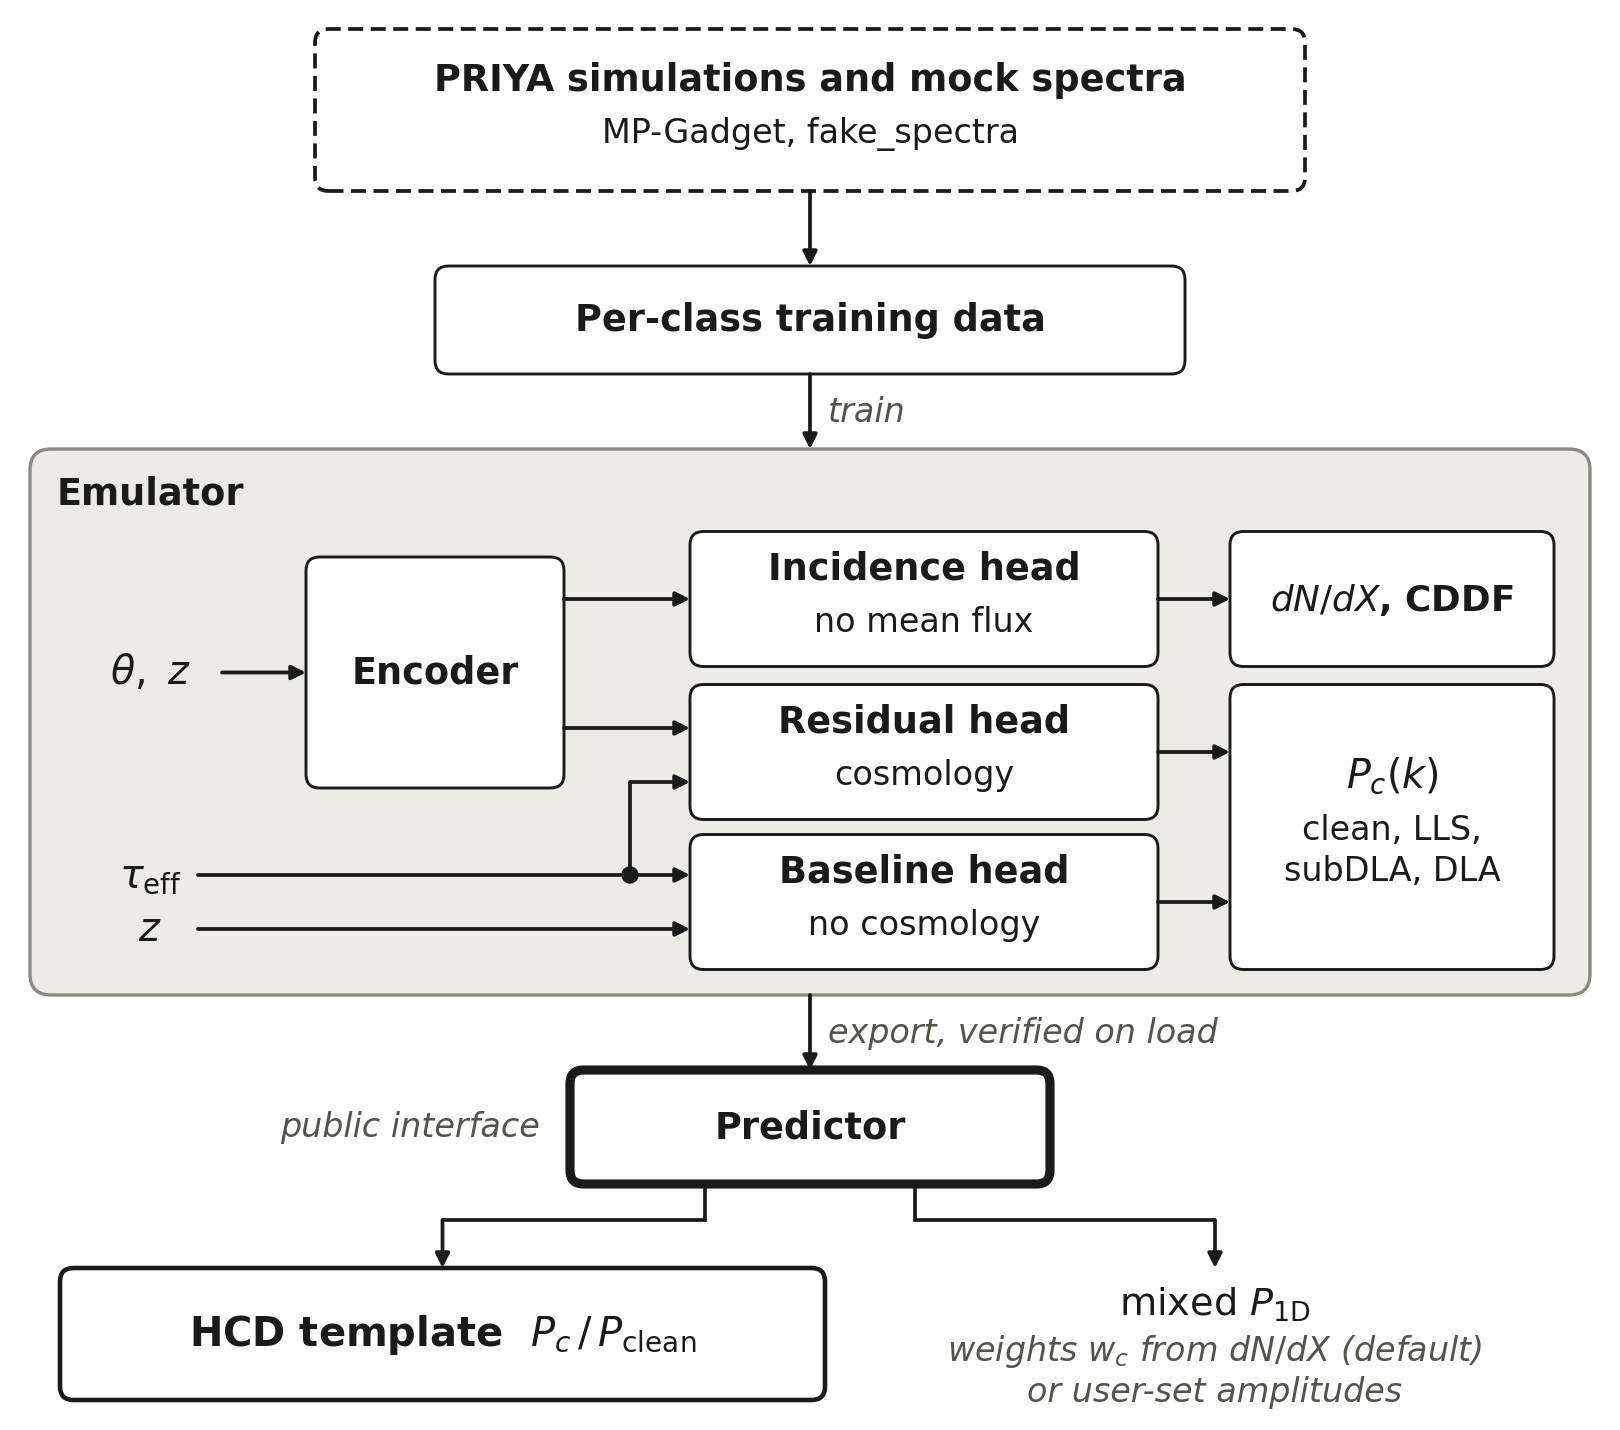

In [6]:
# Fig. 4. How the emulator is built (the schematic of the manuscript; assets/figures/PROVENANCE.md in the repository).
from IPython.display import Image, display

display(Image(filename=str(tutorial_file("notebooks/tutorial/assets/figures/joss_architecture.png")), width=900))

**Fig. 4. PROVISIONAL (PI to refine).** One model takes the nine parameters, the redshift and the mean flux, and
returns the four class spectra, with a multi-fidelity correction towards the high-resolution simulations, and the
incidence of the absorbers (dN/dX and the column density distribution).

In [7]:
pred = emu.predict(PARAMS, z=3.0, tau0_amp=1.0, dtau0=0.0)

print("model:", pred.labels["product"])
print("classes, in the order of P_class:", hp.CLASSES)
print(f"pred.k:       shape {pred.k.shape}, from {pred.k[0]:.2e} to {pred.k[-1]:.2e} s/km")
print(f"pred.P_class: shape {pred.P_class.shape}, in km/s")
print(f"pred.w_c:     the model's sightline fractions of {hp.HCD_CLASSES}: {np.round(pred.w_c, 4)}")
print(f"pred.dndx:    the incidence dN/dX of the same three classes: {np.round(pred.dndx, 4)}")
print(f"mean flux:    tau_eff = {float(pred.tau_eff):.4f}")
print("flags that are set:", sorted(name for name, value in pred.flags.items() if value is True))

model: LF+MF
classes, in the order of P_class: ('clean', 'LLS', 'subDLA', 'DLA')
pred.k:       shape (172,), from 4.76e-04 to 8.18e-02 s/km
pred.P_class: shape (4, 172), in km/s
pred.w_c:     the model's sightline fractions of ('LLS', 'subDLA', 'DLA'): [0.2126 0.0786 0.0376]
pred.dndx:    the incidence dN/dX of the same three classes: [0.4337 0.1343 0.0602]
mean flux:    tau_eff = 0.3624
flags that are set: ['incidence_heldout_error_available', 'incidence_mf_applied', 'k_downweighted', 'mf_applied', 'p1d_validation_available']


### Conventions

**PROVISIONAL (PI to refine).**

- The spectrum is that of $\delta_F = F / \langle F \rangle - 1$, with one mean flux $\langle F \rangle$ for the
  whole sample of sightlines, all classes together.
- $k$ is the angular wavenumber, in s/km.
- The class spectra are *PRIYA-filtered*: the cores of the strongest absorbers are masked in the simulated
  spectra, as for the PRIYA forest emulator, and the mixture below does not add back what the filter removed
  (`pred.labels["omissions"]` names it, and a later cell prints it).

A class spectrum is therefore a conditional spectrum under one normalisation. It is not the spectrum of isolated
absorbers. The definitions are in `docs/p1d_definition.md` of the repository.

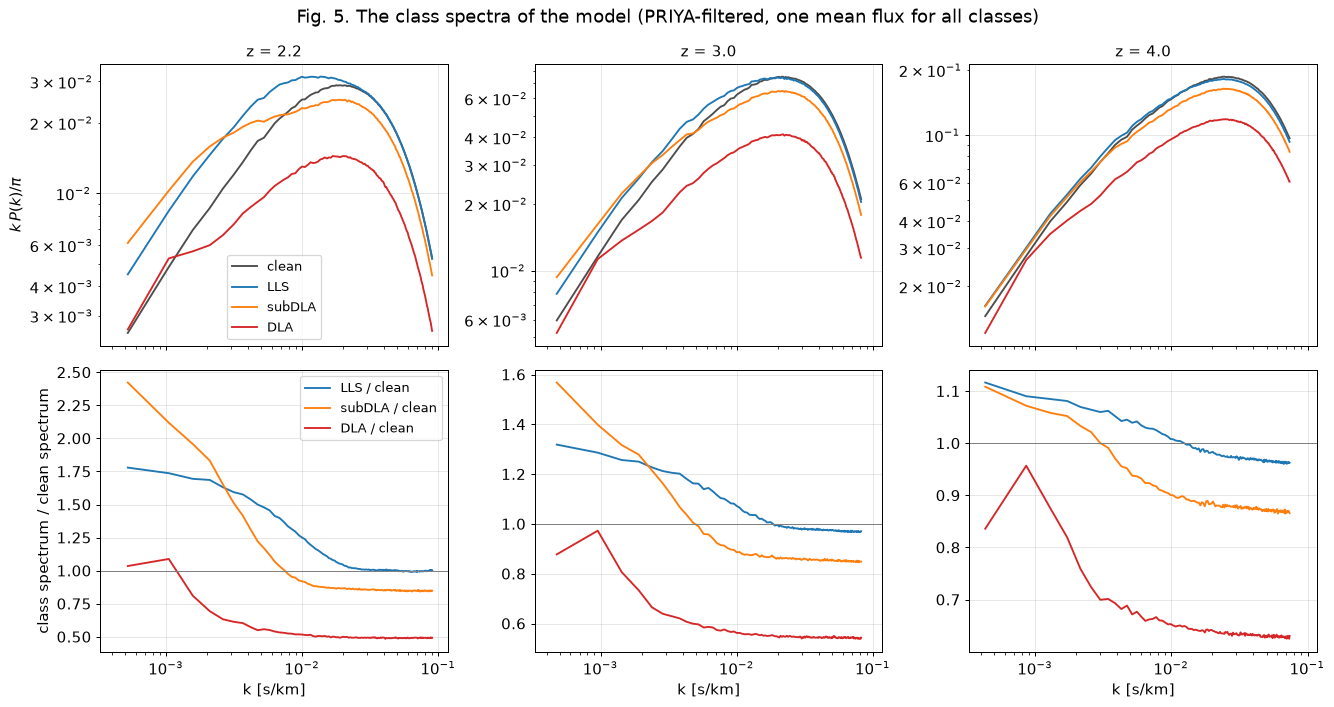

Where each class ratio lies above and below one (ranges of k in s/km):
  z = 2.2  LLS     smallest 0.990, largest 1.779; above one on 106 of 172 modes: 5.23e-04 to 4.71e-02; 4.81e-02 to 4.97e-02; 5.07e-02 to 5.07e-02; and 3 more ranges; below one: 4.76e-02 to 4.76e-02; 5.02e-02 to 5.02e-02; 5.12e-02 to 8.00e-02; and 2 more ranges
  z = 2.2  subDLA  smallest 0.842, largest 2.423; above one on 14 of 172 modes: 5.23e-04 to 7.32e-03; below one: 7.84e-03 to 8.99e-02
  z = 2.2  DLA     smallest 0.485, largest 1.089; above one on 2 of 172 modes: 5.23e-04 to 1.05e-03; below one: 1.57e-03 to 8.99e-02
  z = 3.0  LLS     smallest 0.967, largest 1.319; above one on 38 of 172 modes: 4.76e-04 to 1.81e-02; below one: 1.86e-02 to 8.18e-02
  z = 3.0  subDLA  smallest 0.847, largest 1.568; above one on 10 of 172 modes: 4.76e-04 to 4.76e-03; below one: 5.23e-03 to 8.18e-02
  z = 3.0  DLA     smallest 0.539, largest 0.973; above one on 0 of 172 modes: nowhere; below one: 4.76e-04 to 8.18e-02
  z = 4.0  LL

In [8]:
# Fig. 5. The four class spectra, and the ratio of each HCD class to the clean forest, at three redshifts.
Z_SHOWN = (2.2, 3.0, 4.0)
stack = emu.predict_many(PARAMS, z=list(Z_SHOWN), tau0_amp=1.0, dtau0=0.0)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex=True)
for j, z in enumerate(Z_SHOWN):
    k = stack.k[j]
    for i, name in enumerate(hp.CLASSES):
        axes[0, j].loglog(k, k * stack.P_class[j, i] / np.pi, color=CLASS_COLOURS[name], label=name)
    for i, name in enumerate(hp.CLASSES[1:], start=1):
        axes[1, j].semilogx(k, stack.P_class[j, i] / stack.P_class[j, 0], color=CLASS_COLOURS[name], label=f"{name} / clean")
    axes[1, j].axhline(1.0, color="grey", lw=0.8)
    axes[0, j].set_title(f"z = {z}")
    axes[1, j].set_xlabel("k [s/km]")
axes[0, 0].set_ylabel(r"$k\,P(k)/\pi$")
axes[1, 0].set_ylabel("class spectrum / clean spectrum")
axes[0, 0].legend()
axes[1, 0].legend()
fig.suptitle("Fig. 5. The class spectra of the model (PRIYA-filtered, one mean flux for all classes)")
fig.tight_layout()
plt.show()

def k_ranges(k, mask):
    # the contiguous ranges of k on which mask holds, as text (the first three, then how many more)
    ranges, start = [], None
    for i, flag in enumerate(mask):
        if flag and start is None:
            start = i
        if start is not None and (not flag or i == len(mask) - 1):
            ranges.append(f"{k[start]:.2e} to {k[i if flag else i - 1]:.2e}")
            start = None
    if not ranges:
        return "nowhere"
    return "; ".join(ranges[:3]) + (f"; and {len(ranges) - 3} more ranges" if len(ranges) > 3 else "")


print("Where each class ratio lies above and below one (ranges of k in s/km):")
for j, z in enumerate(Z_SHOWN):
    k = stack.k[j]
    for i, name in enumerate(hp.CLASSES[1:], start=1):
        ratio = stack.P_class[j, i] / stack.P_class[j, 0]
        above = ratio > 1.0
        print(f"  z = {z}  {name:7s} smallest {ratio.min():.3f}, largest {ratio.max():.3f}; above one on {int(above.sum())} of {k.size} modes: "
              f"{k_ranges(k, above)}; below one: {k_ranges(k, ~above)}")

**PROVISIONAL (PI to refine).** Reading Fig. 5: the printed lines say where each class has more and where it has
less power than the clean forest, as the model gives it. With the conventions above, a ratio below one is not a
defect: the classes share one mean flux, and the filter removes the core of the strongest absorbers. The physical
reading of each class is to be written here from the printed numbers.

### The mixture of the classes

**PROVISIONAL (PI to refine).** `hp.add_hcd(pred, A)` mixes the class spectra linearly:

$$P_\mathrm{mix}(k) = P_\mathrm{clean}(k) + \sum_c A_c\,[P_c(k) - P_\mathrm{clean}(k)], \qquad c \in \{\mathrm{LLS}, \mathrm{subDLA}, \mathrm{DLA}\}.$$

The amplitudes $A_c$ are fractions of sightlines. The model's own fractions at a point are `pred.w_c`.

What the mixture is not: it is not the P1D of an observed sample (the cores removed by the filter are left out,
see `pred.labels["omissions"]`); nothing is fitted; and it carries no law in redshift of its own.

the model's own fractions at this point: LLS 0.2126, subDLA 0.0786, DLA 0.0376
what the mixture leaves out:
  - the subDLA filtered remnant: the power of subDLA cores the PRIYA filter removes is not added back
  - the DLA damping-wing core: the DLA class is the PRIYA-filtered spectrum, without its core
LLS     amplitude from 0 to 2 times the model's own: the mixture changes by at most 13.03 per cent, at k = 4.76e-04 s/km, and by 1.28 per cent at the largest k
subDLA  amplitude from 0 to 2 times the model's own: the mixture changes by at most 8.40 per cent, at k = 4.76e-04 s/km, and by 2.44 per cent at the largest k
DLA     amplitude from 0 to 2 times the model's own: the mixture changes by at most 3.54 per cent, at k = 7.94e-02 s/km, and by 3.50 per cent at the largest k


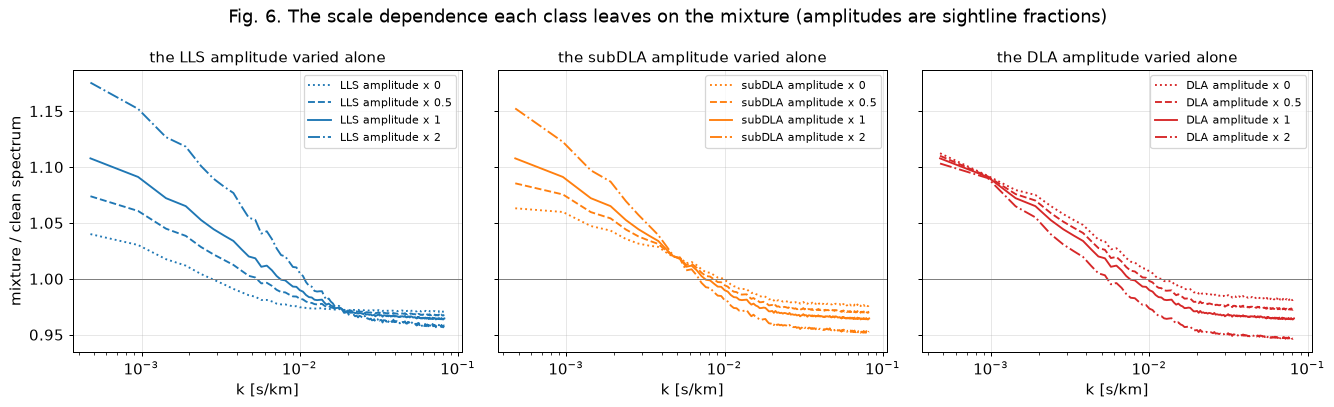

In [9]:
# Fig. 6. The mixture over the clean spectrum at z = 3, with the amplitude of one class at a time at 0, 0.5, 1 and
# 2 times the model's own fraction (the other two classes at the model's own).
FACTORS = (0.0, 0.5, 1.0, 2.0)
clean = pred.P_class[0]
print("the model's own fractions at this point:", ", ".join(f"{name} {value:.4f}" for name, value in zip(hp.HCD_CLASSES, pred.w_c)))
print("what the mixture leaves out:")
for omission in pred.labels["omissions"]:
    print("  -", omission)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharey=True)
for c, name in enumerate(hp.HCD_CLASSES):
    spread = []
    for factor, style in zip(FACTORS, (":", "--", "-", "-.")):
        scale = np.ones(3)
        scale[c] = factor
        mixed = hp.add_hcd(pred, pred.w_c * scale)
        spread.append(mixed / clean)
        axes[c].semilogx(pred.k, mixed / clean, style, color=CLASS_COLOURS[name], label=f"{name} amplitude x {factor:g}")
    axes[c].axhline(1.0, color="grey", lw=0.8)
    axes[c].set_xlabel("k [s/km]")
    axes[c].set_title(f"the {name} amplitude varied alone")
    axes[c].legend(fontsize=9)
    change = np.abs(spread[-1] / spread[0] - 1.0)
    print(f"{name:7s} amplitude from 0 to 2 times the model's own: the mixture changes by at most "
          f"{100 * change.max():.2f} per cent, at k = {pred.k[change.argmax()]:.2e} s/km, "
          f"and by {100 * change[-1]:.2f} per cent at the largest k")
axes[0].set_ylabel("mixture / clean spectrum")
fig.suptitle("Fig. 6. The scale dependence each class leaves on the mixture (amplitudes are sightline fractions)")
fig.tight_layout()
plt.show()

In [10]:
# Running a released script of the repository as it is. The scripts and the tables they read are files of the tag
# v1.0.0, each pinned by its sha256 (ASSETS). They are put at their repository paths under one folder, the cache
# folder, because a script finds its data three folders above itself; then the script is run with this Python.
import shutil
import subprocess
import sys
import tarfile

RELEASED_FIGURE_FILES = (
    "scripts/figures/figures_common.py",
    "docs/figures/data/SHA256SUMS",
    "docs/figures/data/priya_lf_design_60.csv",
    "docs/figures/data/class_ratio_ranges_z3p0_lf60.csv",
    "docs/figures/data/ho21/cddf_z225.txt",
    "docs/figures/data/ho21/cddf_z253.txt",
    "docs/figures/data/ho21/cddf_z34.txt",
    "docs/figures/data/ho21/dndx_all.txt",
    "docs/figures/data/lls_incidence/lls_lz_literature.dat",
    "docs/figures/data/lls_subdla/zafar_2013.txt",
    "docs/figures/data/lls_subdla/omeara2007_fn_all19p0.dat",
    "docs/figures/data/lls_subdla/prochaska2010_lls_region.dat",
)
OUT = pathlib.Path("tutorial_output")  # the figures the released code writes, beside this notebook
OUT.mkdir(exist_ok=True)


def released_tree(relpaths):
    # the files named, each with its pinned sha256, at their repository paths under the cache folder
    root = tutorial_cache()
    for relpath in relpaths:
        source, target = tutorial_file(relpath), root / relpath
        if source != target and not (target.is_file() and sha256_of(target) == ASSETS[relpath]["sha256"]):
            target.parent.mkdir(parents=True, exist_ok=True)
            handle, partial = tempfile.mkstemp(dir=target.parent, prefix=target.name + ".", suffix=".part")
            os.close(handle)
            shutil.copyfile(source, partial)
            os.replace(partial, target)
    return root


def run_released_script(script, arguments, needs=RELEASED_FIGURE_FILES):
    # runs a released script, unchanged, and returns what it printed
    root = released_tree([script, *needs])
    done = subprocess.run(
        [sys.executable, str(root / script), *arguments],
        capture_output=True,
        text=True,
        env=dict(os.environ, MPLBACKEND="Agg"),
    )
    if done.returncode != 0:
        raise RuntimeError(f"the released script {script} ended with code {done.returncode}:\n{done.stderr[-2000:]}")
    return done.stdout


def unpack_archive(relpath, top, marker):
    # A pinned archive of the release, unpacked once into the cache folder. Every entry must be a plain file or
    # folder under the one folder `top`; anything else is refused and nothing is unpacked. `marker` is a file of the
    # archive whose presence says that an earlier unpacking was finished.
    root = tutorial_cache() / top
    if not (root / marker).is_file():
        archive_path = tutorial_file(relpath)
        tutorial_cache().mkdir(parents=True, exist_ok=True)
        scratch = pathlib.Path(tempfile.mkdtemp(dir=tutorial_cache(), prefix="unpack."))
        try:
            with tarfile.open(archive_path) as archive:
                members = archive.getmembers()
                for member in members:
                    inside = pathlib.PurePosixPath(member.name)
                    plain = member.isfile() or member.isdir()
                    if inside.is_absolute() or ".." in inside.parts or inside.parts[0] != top or not plain:
                        raise RuntimeError(f"{relpath} holds an entry that is not a plain file under {top}: {member.name}")
                safe = {"filter": "data"} if hasattr(tarfile, "data_filter") else {}
                archive.extractall(scratch, members=members, **safe)
            if root.exists():  # an unfinished copy from an earlier run
                shutil.rmtree(root)
            os.replace(scratch / top, root)
        finally:
            shutil.rmtree(scratch, ignore_errors=True)
    return root


def show_script_output(printed):
    # what a released script printed; its indented detail lines are counted, not shown
    lines = printed.splitlines()
    for line in lines:
        if line.strip() and not line.startswith(" "):
            print("the script printed:", line)
    detail = sum(1 for line in lines if line.startswith(" ") and line.strip())
    if detail:
        print(f"({detail} indented detail lines of the script are not shown here)")

the script printed: the count above 10^17.5 against the class lines: ratio 0.9998 to 1.0020
the script printed: 60 design points; with a flag the drawn line does not have, at some redshift: 12; refused at some redshift: 0
the script printed: wrote the figure: tutorial_output/dndx_vs_ho21.png
(12 indented detail lines of the script are not shown here)


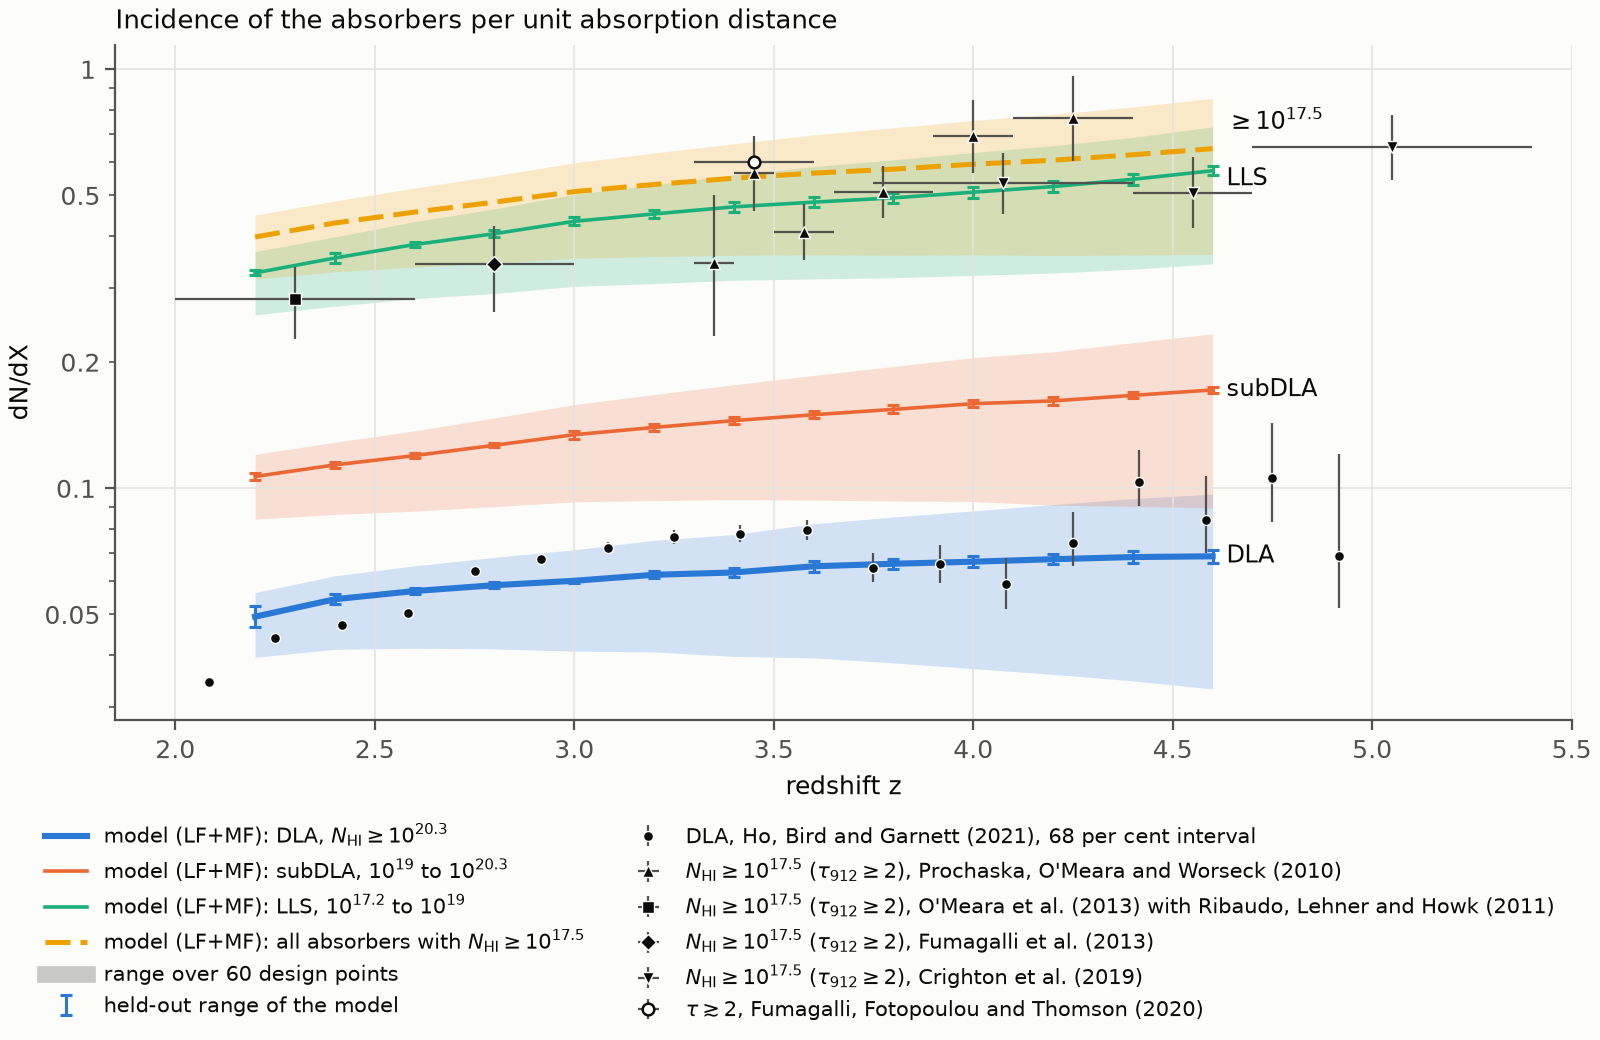

At z = 3 at the midpoint, the model's dN/dX with its held-out range (value x exp(-e) to value x exp(+e)):
  LLS     0.4337   range 0.4242 to 0.4435
  subDLA  0.1343   range 0.1314 to 0.1372
  DLA     0.0602   range 0.0595 to 0.0609


In [11]:
# Fig. 7. The incidence dN/dX the model predicts, against redshift, with published measurements: drawn by the
# released script scripts/figures/fig_dndx_vs_ho21.py, unchanged, with the published model.
show_script_output(run_released_script("scripts/figures/fig_dndx_vs_ho21.py", ["--published", "--out", str(OUT / "dndx_vs_ho21.png")]))
display(Image(filename=str(OUT / "dndx_vs_ho21.png"), width=900))

print("At z = 3 at the midpoint, the model's dN/dX with its held-out range (value x exp(-e) to value x exp(+e)):")
for c, name in enumerate(hp.HCD_CLASSES):
    print(f"  {name:7s} {pred.dndx[c]:.4f}   range {pred.dndx_lower[c]:.4f} to {pred.dndx_upper[c]:.4f}")

**Fig. 7. PROVISIONAL (PI to refine).** The incidence dN/dX the model predicts for the three classes, and for all
absorbers above $10^{17.5}$ cm$^{-2}$, against redshift, with published measurements. Drawn by the released script
`fig_dndx_vs_ho21.py`, unchanged; the full caption is in `docs/model_figures.md` of the repository.

the script printed: z = 2.2: 60 design points; with a flag the drawn line does not have: 12; refused: 0
the script printed: z = 2.8: 60 design points; with a flag the drawn line does not have: 12; refused: 0
the script printed: z = 3.4: 60 design points; with a flag the drawn line does not have: 12; refused: 0
the script printed: wrote the figure: tutorial_output/cddf_vs_ho21.png
(36 indented detail lines of the script are not shown here)


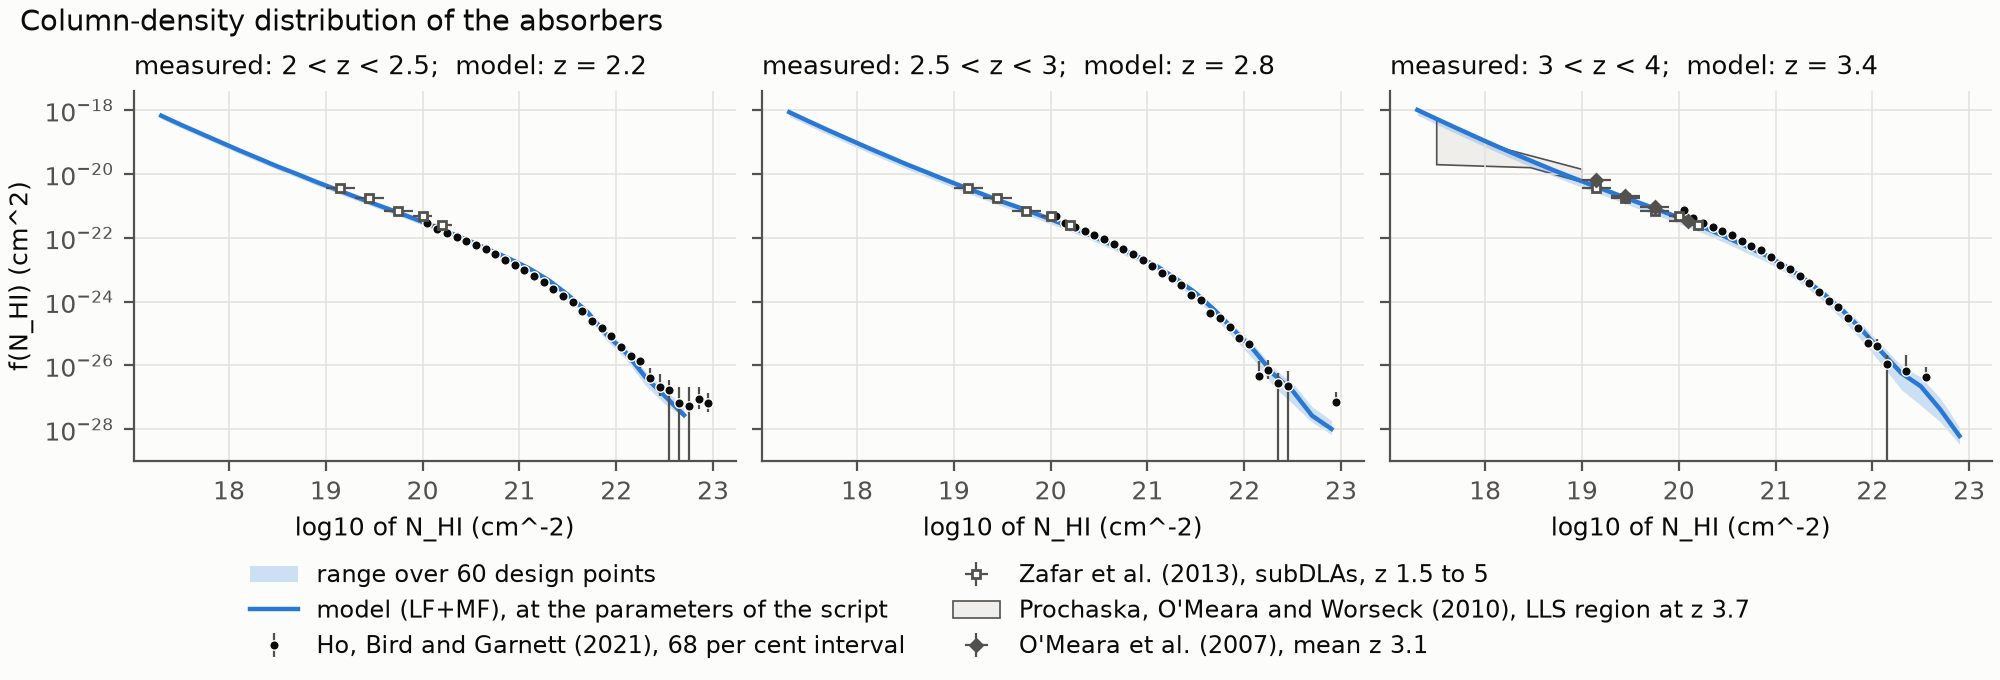

In [12]:
# Fig. 7b. The column density distribution the model predicts, with published measurements: drawn by the released
# script scripts/figures/fig_cddf_vs_ho21.py, unchanged, with the published model.
show_script_output(run_released_script("scripts/figures/fig_cddf_vs_ho21.py", ["--published", "--out", str(OUT / "cddf_vs_ho21.png")]))
display(Image(filename=str(OUT / "cddf_vs_ho21.png"), width=900))

**Fig. 7b. PROVISIONAL (PI to refine).** The column density distribution the model predicts, in three redshift
bins, with the published measurements of Fig. 2. Drawn by the released script `fig_cddf_vs_ho21.py`, unchanged;
the full caption is in `docs/model_figures.md` of the repository.

### Two different operations

**PROVISIONAL (PI to refine).** There are two ways to change how much the LLS contribute to a mixture, and they
are not the same operation.

1. **Changing an amplitude $A_c$** rescales how many sightlines of a class enter the mixture, at fixed class
   spectra. No new prediction is made. The amplitude is a nuisance of the mixture.
2. **Changing the nine parameters** changes what the emulator predicts: the incidence (Fig. 3), the sightline
   fractions and the class spectra together. The incidence is a prediction.

The next cell does each once and prints what changes and what stays the same.

In [13]:
def largest_change(a, b):
    # the largest relative difference of two spectra over k, in per cent
    return 100.0 * float(np.max(np.abs(np.asarray(a) / np.asarray(b) - 1.0)))


mix_0 = hp.add_hcd(pred, pred.w_c)

# A. The LLS amplitude doubled by hand, at fixed parameters. The same prediction is used; nothing is predicted anew.
again = emu.predict(PARAMS, z=3.0, tau0_amp=1.0, dtau0=0.0)
scale = np.ones(3)
scale[I_LLS] = 2.0
mix_a = hp.add_hcd(again, again.w_c * scale)

# B. One parameter moved, at the model's own fractions: the first parameter of the ranking of Fig. 3, moved to the
# end of its trained range where the predicted LLS incidence is the larger.
moved_name = RANKING[0]
moved_value = float(response[moved_name][0][np.argmax(response[moved_name][1])])
pred_b = emu.predict(dict(PARAMS, **{moved_name: moved_value}), z=3.0, tau0_amp=1.0, dtau0=0.0)
mix_b = hp.add_hcd(pred_b, pred_b.w_c)

print(f"A: the LLS amplitude set to 2 times the model's own fraction, parameters fixed")
print(f"B: {moved_name} moved from {PARAMS[moved_name]:g} to {moved_value:g}, amplitudes at the model's own fractions")
print()
print(f"{'':44s} {'A':>22s} {'B':>22s}")
print(f"{'LLS amplitude in the mixture':44s} {'x 2.000 (by hand)':>22s} {'x %.3f (pred.w_c)' % (pred_b.w_c[I_LLS] / pred.w_c[I_LLS]):>22s}")
for c, name in enumerate(hp.HCD_CLASSES):
    same = "the same" if again.dndx[c] == pred.dndx[c] else "x %.3f" % (again.dndx[c] / pred.dndx[c])
    print(f"{'predicted incidence dN/dX, ' + name:44s} {same:>22s} {'x %.3f' % (pred_b.dndx[c] / pred.dndx[c]):>22s}")
for i, name in enumerate(hp.CLASSES):
    same = "the same" if np.array_equal(again.P_class[i], pred.P_class[i]) else "changed"
    print(f"{'class spectrum, ' + name + ', largest change':44s} {same:>22s} {'%.2f per cent' % largest_change(pred_b.P_class[i], pred.P_class[i]):>22s}")
print(f"{'the mixture, largest change':44s} {'%.2f per cent' % largest_change(mix_a, mix_0):>22s} {'%.2f per cent' % largest_change(mix_b, mix_0):>22s}")
print()
print("What stays the same in A: the prediction itself. Its incidence, its sightline fractions and its four class spectra")
print("  are equal to those above:", bool(np.array_equal(again.dndx, pred.dndx) and np.array_equal(again.w_c, pred.w_c)
                                          and np.array_equal(again.P_class, pred.P_class)))
print(f"What stays the same in B: the other eight parameters, the redshift and the mean flux (tau_eff equal: "
      f"{bool(float(pred_b.tau_eff) == float(pred.tau_eff))}), and the rule that the amplitudes are the model's own fractions.")

A: the LLS amplitude set to 2 times the model's own fraction, parameters fixed
B: Ap moved from 1.9e-09 to 2.6e-09, amplitudes at the model's own fractions

                                                                  A                      B
LLS amplitude in the mixture                      x 2.000 (by hand)     x 1.071 (pred.w_c)
predicted incidence dN/dX, LLS                             the same                x 1.101
predicted incidence dN/dX, subDLA                          the same                x 1.119
predicted incidence dN/dX, DLA                             the same                x 1.129
class spectrum, clean, largest change                      the same         10.36 per cent
class spectrum, LLS, largest change                        the same         10.85 per cent
class spectrum, subDLA, largest change                     the same         16.00 per cent
class spectrum, DLA, largest change                        the same         11.00 per cent
the mixture, largest cha

### How far to trust it: the held-out prediction residual and the validated range

**PROVISIONAL (PI to refine).** For each class spectrum and for the mixture the model carries a *held-out
prediction residual* $e(k)$: the root mean square of $\ln(\mathrm{prediction} / \mathrm{truth})$ over simulations
the model was made without. As a range on a spectrum it is the value times $\exp(-e)$ to the value times
$\exp(+e)$, each bound on its own. It is an empirical validation diagnostic, not a calibrated predictive
uncertainty.

The LF+MF model is validated from $z = 2.2$ to $4.6$. Above that range a prediction is returned with flags;
below it, and between snapshot redshifts, it is refused.

In [14]:
Z_VALIDATED = [z for z in hp.Z_GRID if 2.2 - 1e-9 <= z <= 4.6 + 1e-9]
validated = emu.predict_many(PARAMS, z=Z_VALIDATED, tau0_amp=1.0, dtau0=0.0)
e_mix = validated.P_mix_validation_rms_log  # one row per redshift of Z_VALIDATED, one value per wavenumber
print("The held-out prediction residual e of the mixture, by redshift (the value x exp(-e) to x exp(+e)):")
for j, z in enumerate(Z_VALIDATED):
    e, k = e_mix[j], validated.k[j]
    worst = int(np.nanargmax(e))
    print(f"  z = {z:.1f}  median e = {np.nanmedian(e):.3f} (x {np.exp(-np.nanmedian(e)):.3f} to x {np.exp(np.nanmedian(e)):.3f}); "
          f"largest e = {e[worst]:.3f} (x {np.exp(-e[worst]):.3f} to x {np.exp(e[worst]):.3f}) at k = {k[worst]:.2e} s/km")
print()
print("In the model's own words:", pred.labels["p1d_validation"][:420], "...")
print()

high = emu.predict(PARAMS, z=4.8, tau0_amp=1.0, dtau0=0.0)
set_at_3 = {name for name, value in pred.flags.items() if value is True}
print("flags set at z = 4.8 and not at z = 3.0:", sorted({name for name, value in high.flags.items() if value is True} - set_at_3))
try:
    emu.predict(PARAMS, z=3.1, tau0_amp=1.0, dtau0=0.0)
except hp.PredictorInputError as error:
    print("z = 3.1 is refused:", error)
try:
    emu.predict(PARAMS, z=2.0, tau0_amp=1.0, dtau0=0.0)
except hp.MFRangeError as error:
    print("z = 2.0 is refused:", error)

The held-out prediction residual e of the mixture, by redshift (the value x exp(-e) to x exp(+e)):
  z = 2.2  median e = 0.010 (x 0.990 to x 1.010); largest e = 0.026 (x 0.974 to x 1.027) at k = 5.23e-04 s/km
  z = 2.4  median e = 0.009 (x 0.991 to x 1.009); largest e = 0.035 (x 0.965 to x 1.036) at k = 5.10e-04 s/km
  z = 2.6  median e = 0.009 (x 0.991 to x 1.009); largest e = 0.044 (x 0.957 to x 1.045) at k = 4.98e-04 s/km
  z = 2.8  median e = 0.008 (x 0.992 to x 1.008); largest e = 0.026 (x 0.975 to x 1.026) at k = 8.37e-02 s/km
  z = 3.0  median e = 0.009 (x 0.991 to x 1.009); largest e = 0.036 (x 0.964 to x 1.037) at k = 4.76e-04 s/km
  z = 3.2  median e = 0.009 (x 0.991 to x 1.009); largest e = 0.026 (x 0.974 to x 1.026) at k = 7.96e-02 s/km
  z = 3.4  median e = 0.008 (x 0.992 to x 1.008); largest e = 0.027 (x 0.974 to x 1.027) at k = 7.84e-02 s/km
  z = 3.6  median e = 0.010 (x 0.990 to x 1.010); largest e = 0.025 (x 0.976 to x 1.025) at k = 4.46e-04 s/km
  z = 3.8  median e =

### Beside the template of Rogers et al. (2018)

**PROVISIONAL (PI to refine; each statement about the paper is to be checked against it).** Rogers et al. (2018)
give a template for the effect of HCD absorbers on the P1D: for each of four classes of column density, a fitted
function of $k$ and $z$ for the ratio of the class spectrum to the forest spectrum (their Eq. 6), from one
simulation, used with free amplitudes and with no dependence on cosmology. What differs here: the class spectra
are emulated across nine parameters and the mean flux; they are PRIYA-filtered; and the incidence is predicted.
`docs/rogers_comparison.md` of the repository gives the comparison in full.

the script printed: wrote the figure: tutorial_output/class_ratio_vs_rogers18.png


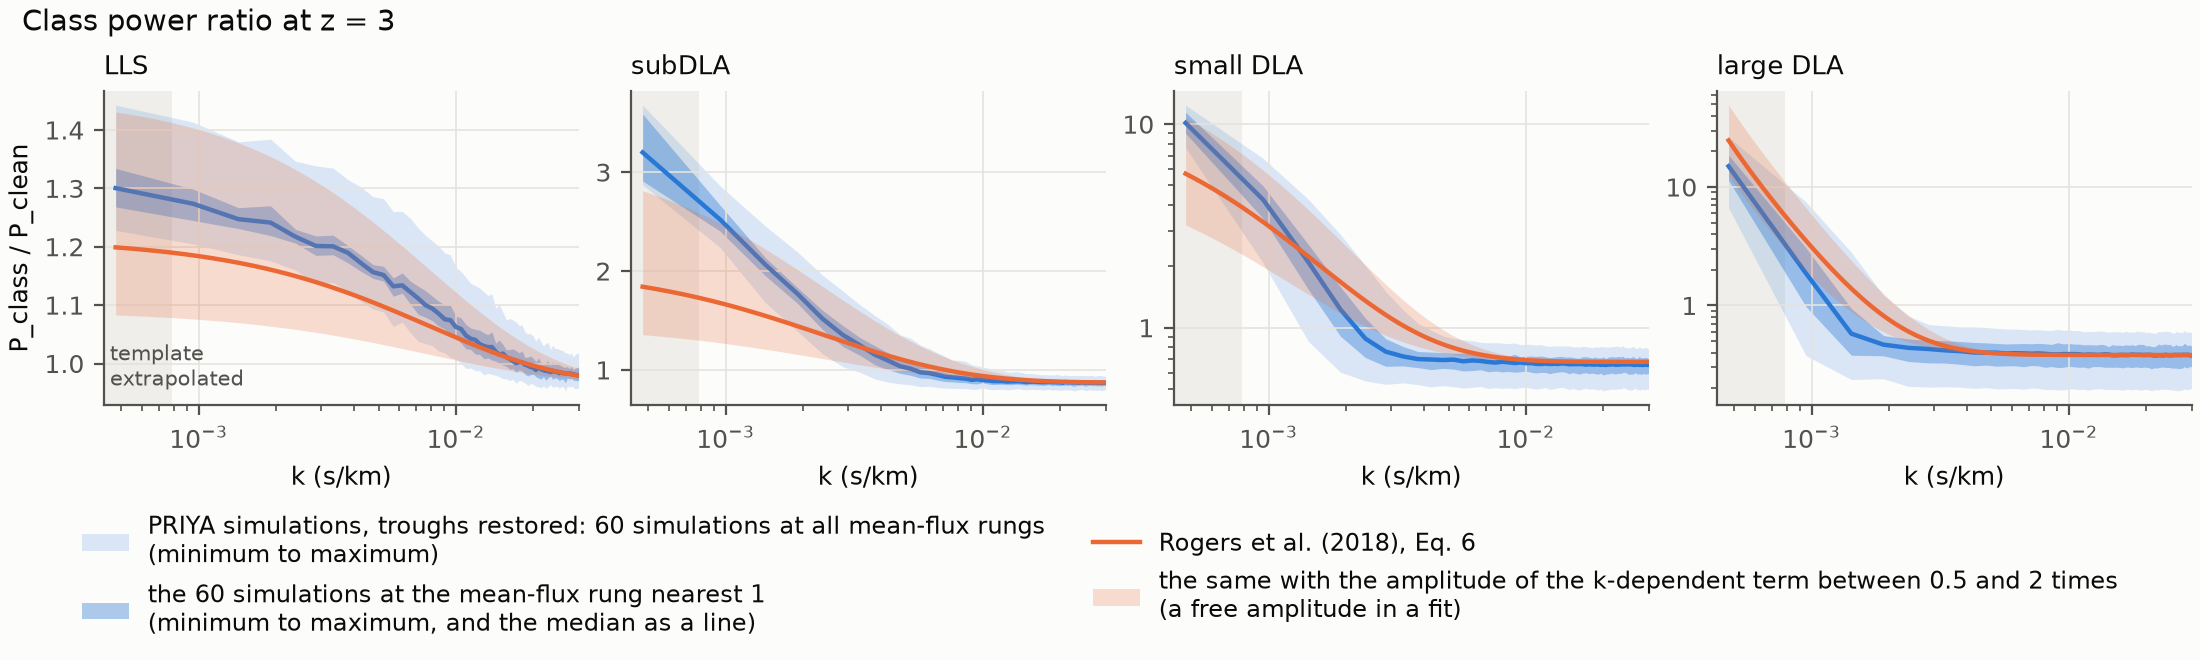

In [15]:
# Fig. 8, left. The PRIYA training simulations with the filtered troughs restored, against Eq. 6 of Rogers et al.
# (2018), at z = 3: drawn by the released script scripts/figures/fig_class_ratio_vs_rogers18.py, unchanged.
show_script_output(run_released_script("scripts/figures/fig_class_ratio_vs_rogers18.py", ["--out", str(OUT / "class_ratio_vs_rogers18.png")]))
display(Image(filename=str(OUT / "class_ratio_vs_rogers18.png"), width=900))

Eq. 6 of Rogers et al. (2018) for the LLS class at z = 3, on these wavenumbers: 0.979 to 1.199;
it is a function of k and z alone, so across the inputs below it does not change


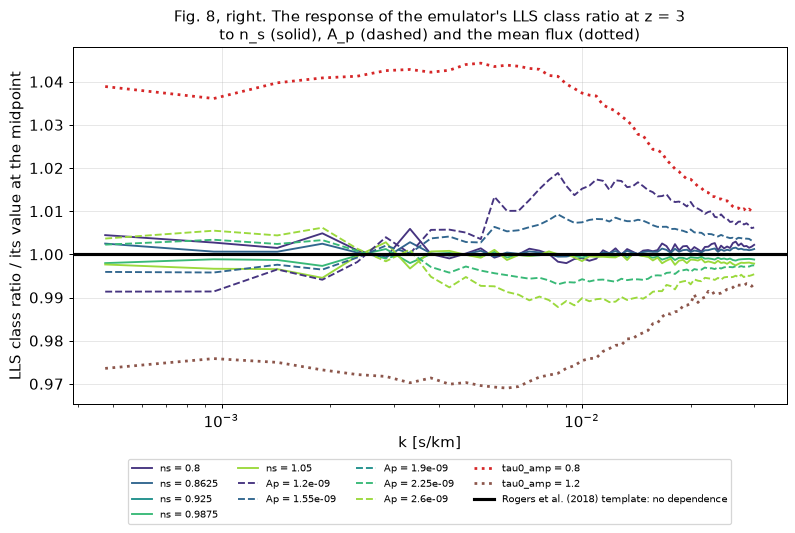

The largest change of the emulator's LLS class ratio below k = 0.03 s/km at z = 3 across the trained range of
each input (five values; the others at the midpoint, tau0_amp = 1), largest first:
  tau0_amp     9.25 per cent
  Ap           1.89 per cent
  hub          1.86 per cent
  alphaq       0.63 per cent
  ns           0.59 per cent
  herei        0.42 per cent
  heref        0.34 per cent
  hireionz     0.30 per cent
  omegamh2     0.30 per cent
  bhfeedback   0.06 per cent
dtau0 is not varied: at one redshift it acts only through tau_eff, which tau0_amp already covers


In [16]:
# Fig. 8, right. The response of the emulator's LLS class ratio to n_s, A_p and the mean flux, and a ranking over
# all inputs. The template of Rogers et al. (2018) is hcd_template.class_ratio(k, z): it takes a wavenumber and a
# redshift, and nothing else.
from hcd_analysis.hcd_template import class_ratio

shown = pred.k < 0.03  # the box modes below 0.03 s/km at the midpoint
ratio_mid = pred.P_class[1] / pred.P_class[0]
eq6_lls = class_ratio(pred.k[shown], 3.0)["LLS"]
print(f"Eq. 6 of Rogers et al. (2018) for the LLS class at z = 3, on these wavenumbers: {eq6_lls.min():.3f} to {eq6_lls.max():.3f};")
print("it is a function of k and z alone, so across the inputs below it does not change")


def lls_ratio_relative(name, value):
    # the LLS class ratio with one input changed, over its value at the midpoint, box mode by box mode (hub and
    # omegamh2 move the wavenumber in s/km of a mode; the ratio is compared at the same mode)
    params = dict(PARAMS, **({name: value} if name in PARAMS else {}))
    other = emu.predict(params, z=3.0, tau0_amp=value if name == "tau0_amp" else 1.0, dtau0=0.0)
    return (other.P_class[1] / other.P_class[0]) / ratio_mid


INPUTS = list(zip(hp.PARAM_NAMES, hp.PARAM_LIMITS)) + [("tau0_amp", TAU0_AMP_RANGE)]
largest = {}
fig, ax = plt.subplots(figsize=(9, 6.2))
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for name, (low, high) in INPUTS:
        largest[name] = max(
            float(np.max(np.abs(lls_ratio_relative(name, value)[shown] - 1.0))) for value in np.linspace(low, high, 5)
        )
    for name, style in (("ns", "-"), ("Ap", "--")):
        low, high = hp.PARAM_LIMITS[hp.PARAM_NAMES.index(name)]
        for value, shade in zip(np.linspace(low, high, 5), np.linspace(0.15, 0.85, 5)):
            ax.semilogx(pred.k[shown], lls_ratio_relative(name, value)[shown], style, color=plt.cm.viridis(shade),
                        label=f"{name} = {value:.4g}")
    for value, colour in ((0.8, "tab:red"), (1.2, "tab:brown")):
        ax.semilogx(pred.k[shown], lls_ratio_relative("tau0_amp", value)[shown], ":", lw=2.2, color=colour,
                    label=f"tau0_amp = {value:g}")
ax.axhline(1.0, color="black", lw=2.5, label="Rogers et al. (2018) template: no dependence")
ax.set_xlabel("k [s/km]")
ax.set_ylabel("LLS class ratio / its value at the midpoint")
ax.set_title("Fig. 8, right. The response of the emulator's LLS class ratio at z = 3\nto n_s (solid), A_p (dashed) and the mean flux (dotted)")
ax.legend(fontsize=8, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.14))
fig.tight_layout()
plt.show()

print("The largest change of the emulator's LLS class ratio below k = 0.03 s/km at z = 3 across the trained range of")
print("each input (five values; the others at the midpoint, tau0_amp = 1), largest first:")
for name in sorted(largest, key=lambda name: -largest[name]):
    print(f"  {name:11s} {100 * largest[name]:5.2f} per cent")
print("dtau0 is not varied: at one redshift it acts only through tau_eff, which tau0_amp already covers")
if caught:
    print(f"{len(caught)} of these predictions warned, the first: {str(caught[0].message)[:160]} ...")

**Fig. 8. PROVISIONAL (PI to refine).** The two parts of Fig. 8 answer different questions. On the left (drawn by
the released script `fig_class_ratio_vs_rogers18.py`, unchanged; the full caption is in `docs/rogers_comparison.md`
of the repository) the filtered troughs are restored, so levels can be compared with the template. On the right
the emulator's class spectra are PRIYA-filtered, so their level is not compared with the template: only the
response to the inputs is shown, which a template with no dependence on cosmology does not carry. The printed
list ranks the inputs by the size of that response.

## Part III. The public likelihood and the mock-recovery example

**PROVISIONAL (PI to refine).** This part uses the package's own Gaussian likelihood and the mock-recovery example
of the repository, with the files of the release. Nothing is fitted here.

### The Gaussian likelihood

`hcd_analysis.likelihood.GaussianP1DLikelihood` compares a data vector $d$ with covariance $C$ to a model vector
$m(\theta)$:

$$\ln L(\theta) = -\tfrac{1}{2}\,[d - m(\theta)]^{T} C^{-1} [d - m(\theta)] - \tfrac{1}{2} \ln\det C - \tfrac{N}{2}\ln 2\pi .$$

The class builds the model vector in four steps: the prediction at $\theta$ at the redshifts of the data; the
mixture of the class spectra (`hp.add_hcd`); linear interpolation in $k$ to the wavenumbers of the data; and the
data set's own factor on the model, when it has one. `docs/likelihood.md` of the repository describes the class,
its options and its approximations.

In [17]:
# The files of the mock-recovery example: the example download of the release, unpacked into the cache folder, and
# the example script of the repository at the tag v1.0.0, loaded from its file. Its function open_download returns
# the model, the mock and the stored reference, each read against the sha256 written in the script.
import importlib.util

from hcd_analysis import likelihood as hl


spec = importlib.util.spec_from_file_location("mock_recovery", tutorial_file("examples/mock_recovery.py"))
example = importlib.util.module_from_spec(spec)
spec.loader.exec_module(example)

example_root = unpack_archive("hcd_priya_example_download.tar.gz", "hcd_priya_example_download", "example_download.json")
emu_heldout, data, reference = example.open_download(str(example_root))
print(f"the mock: {data.n} bins at {len(data.z)} redshifts, from z = {min(data.z):.1f} to {max(data.z):.1f}")
print("what the mock is, in its own words:")
print("  ", data.provenance["what"])
print("what the stored reference is, in its own words:")
print("  ", reference.provenance["what"])
print("how its chains were run:", reference.provenance["chains"])
print("its limits:", reference.provenance["limits"])

the mock: 121 bins at 11 redshifts, from z = 2.2 to 4.2
what the mock is, in its own words:
   A mock P1D data set for a recovery test. The data vector is the PRIYA-filtered total P1D of one PRIYA high-resolution simulation (named under "simulation"), at the mean-flux rung nearest the fit of Kim et al. (2007), on the wavenumber bins of the KODIAQ-SQUAD P1D of Karacayli et al. (2022), multiplied by the resolution table in model_factor. Simulation only: no measured P1D is in this file.
what the stored reference is, in its own words:
   The stored reference of the mock-recovery example of hcd_priya: a summary of a converged posterior for the mock of the example download, at its 11 redshifts from 2.2 to 4.2. For each of the eleven parameters: the truth of the mock, the posterior mean, and the central 68 and 95 per cent intervals. For each of the 121 bins of the data vector: the percentiles 2.5, 16, 50, 84 and 97.5 of the posterior predictive.
how its chains were run: Cobaya's MCMC sampler,

In [18]:
# Which model is which.
production = emu.provenance["release"]
print("Parts I and II: the published production model, from hp.load_published()")
print("  release", production["release_version"], "| sha256 of its release.json:", production["release_sha256"])
print("  kind:", emu.provenance.get("model_kind", "a released model"), "| manifest:", emu.manifest_sha256)
print()
print("Part III: the held-out model of the example download, from the example's open_download()")
print("  kind:", emu_heldout.provenance["model_kind"], "| manifest:", emu_heldout.manifest_sha256)
print("  its stated purpose:", emu_heldout.load_purpose)
print("  simulations held out of its training:", len(emu_heldout.provenance["research"]["split"]["held_out_sims"]),
      "(the simulation the mock was made from)")
print("  (the next cell prints the flags of its prediction at the truth: research_model is among them)")

Parts I and II: the published production model, from hp.load_published()
  release 1.0.0 | sha256 of its release.json: c81c33ce65455098620a6e7e54e95bc87f10b06ac10970082ffbc9c6fe5470ad
  kind: a released model | manifest: 48e46fba0bb5eb43d8f7a92ffba100b0cc3817ce81b809530d8bfaff0d737c57

Part III: the held-out model of the example download, from the example's open_download()
  kind: research | manifest: c1e28ee591640d4ccb98c2f05de3d617448c83a74b0c8e2190e2d8e3b393c451
  its stated purpose: the mock-recovery example: a held-out recovery of the mock of the example download
  simulations held out of its training: 1 (the simulation the mock was made from)
  (the next cell prints the flags of its prediction at the truth: research_model is among them)


**PROVISIONAL (PI to refine).** Parts I and II use the published production model. Part III uses the held-out
model of the example download, because the mock-recovery example of the paper does: the mock comes from a
simulation, and the held-out model was trained without that simulation.

In [19]:
# COMPUTED HERE: the likelihood at the point the mock was made at, by the example's own part_one. Warnings are
# caught and printed below, not silenced.
like = hl.GaussianP1DLikelihood(emu_heldout, data, gaussian_terms=example.GAUSSIAN_TERMS)
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    truth = example.part_one(like)

print()
print(f"warnings raised while this ran: {len(caught)}")
for warning in caught:
    print(f"  {warning.category.__name__}: {warning.message}")

=== Part 1: the likelihood at the point the mock was made at
bins in the data vector: 121
redshifts: [4.2, 4.0, 3.8000000000000003, 3.6, 3.4000000000000004, 3.2, 3.0, 2.8, 2.6, 2.4000000000000004, 2.2]
the truth, by name: {'ns': 0.909475936, 'Ap': 1.98137389e-09, 'herei': 3.75465601, 'heref': 3.00952068, 'alphaq': 2.43025565, 'hub': 0.681591829, 'omegamh2': 0.1403, 'hireionz': 7.60269787, 'bhfeedback': 0.0448727377, 'tau0_amp': 1.011182770662847, 'dtau0': 0.0}
parameters of the truth outside this example's flat boxes: []


flags set at the truth (read them before you use the numbers): ['cddf_bins_without_support', 'incidence_mf_applied', 'k_downweighted', 'mf_applied', 'research_content_checks', 'research_model', 'research_split']
the model's class fractions (LLS, subDLA, DLA) at the first redshift, used for the mixture: [0.34086566594878925, 0.14880670702148607, 0.07102776219984568]
model mode spacings per bin spacing, the smallest over all bins and redshifts (likelihood.modes_per_bin; a report of the bin layout, not a test of the interpolation): 4.27
chi-square at the truth (0 would mean the model reproduces the mock exactly): 1.5008160153271053
chi-square per bin at the truth: 0.012403438143199217
log likelihood at the truth, with its normalisation: -93.16361048340667
log density of each Gaussian term at the truth: {'hub': 2.12129231466528, 'bhfeedback': 3.6743996759032833}

warnings raised while this ran: 1


**PROVISIONAL (PI to refine).** The warning printed above comes from the held-out model. It concerns the dN/dX
and the column density distribution of that model, which carry no held-out error. The likelihood uses neither.

In [20]:
# COMPUTED HERE: how the HCD content enters the likelihood. The public option hcd_relative_to_priya sets the
# amplitude of a class in the mixture relative to the model's own sightline fraction.
print("three evaluations of the public likelihood at the mock's truth; nothing is fitted and these are not constraints")
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    for r_lls in (0.0, 1.0, 2.0):
        scaled = hl.GaussianP1DLikelihood(
            emu_heldout, data, gaussian_terms=example.GAUSSIAN_TERMS,
            hcd_relative_to_priya={"LLS": r_lls, "subDLA": 1.0, "DLA": 1.0},
        )
        print(f"  LLS amplitude at {r_lls:g} times the model's own fraction (subDLA and DLA at 1): chi-square = {scaled.chi2(truth):.4f}")
print(f"warnings raised while this ran: {len(caught)}, of the kind", sorted({w.category.__name__ for w in caught}) or "none")

three evaluations of the public likelihood at the mock's truth; nothing is fitted and these are not constraints


  LLS amplitude at 0 times the model's own fraction (subDLA and DLA at 1): chi-square = 2.9302
  LLS amplitude at 1 times the model's own fraction (subDLA and DLA at 1): chi-square = 1.5008
  LLS amplitude at 2 times the model's own fraction (subDLA and DLA at 1): chi-square = 4.8629
warnings raised while this ran: 0, of the kind none


figure written: tutorial_output/posterior_intervals.png


figure written: tutorial_output/posterior_predictive_per_redshift.png
Fig. 9: tutorial_output/posterior_intervals.png


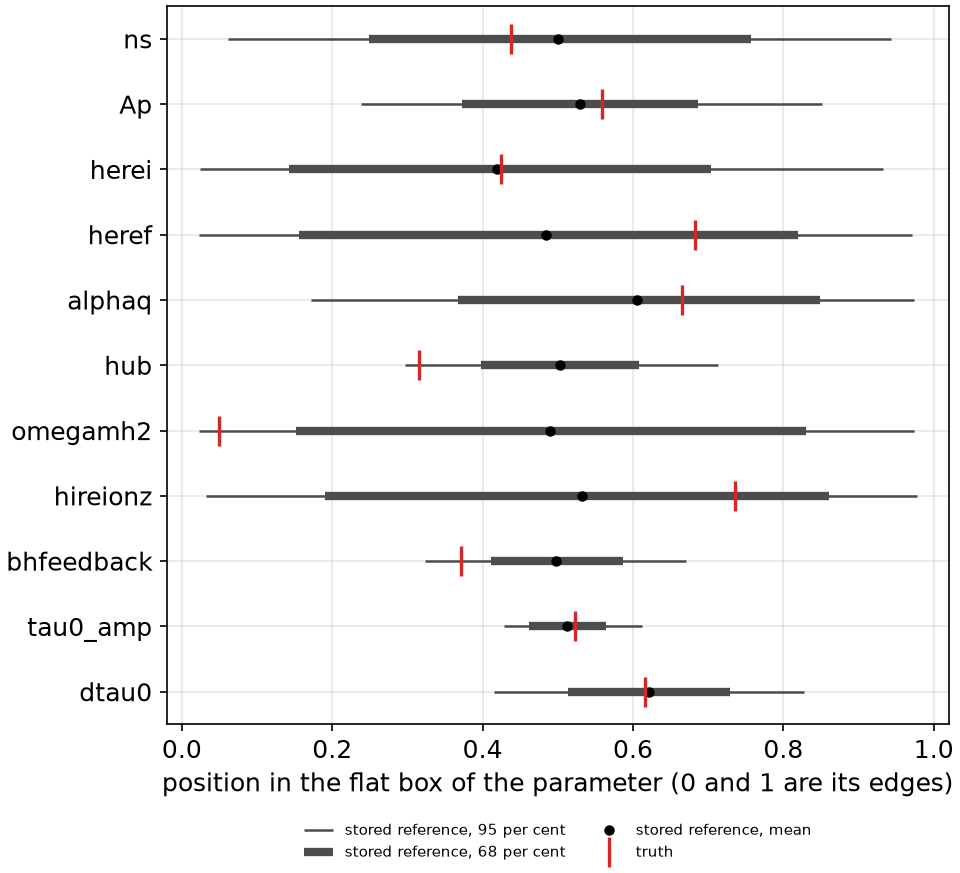

Fig. 10: tutorial_output/posterior_predictive_per_redshift.png


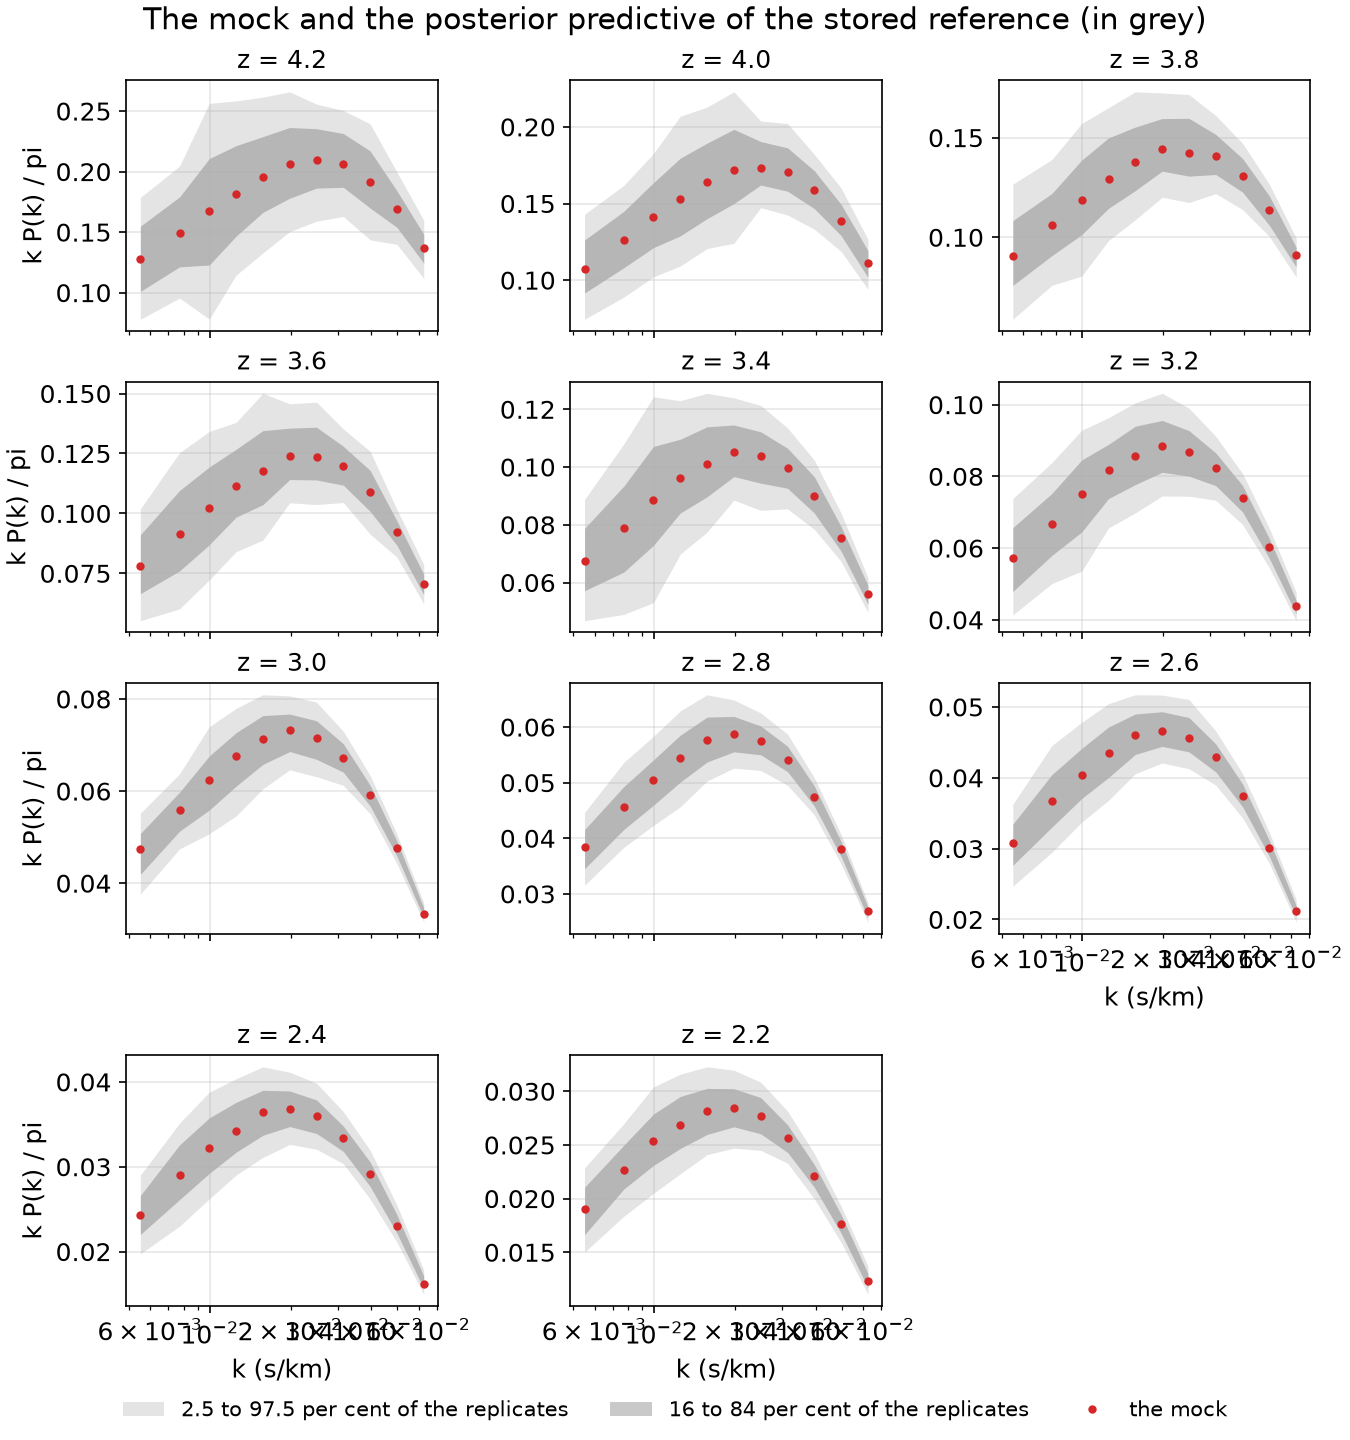

In [21]:
# REDRAWN HERE from the stored reference of the release (a summary of converged chains made before the release);
# NOT RECOMPUTED. The example's own draw_reference draws both figures from the stored reference and the mock alone.
intervals_png, per_redshift_png = example.draw_reference(reference, data, str(OUT))
plt.close("all")
print("Fig. 9:", intervals_png)
display(Image(filename=intervals_png, width=900))
print("Fig. 10:", per_redshift_png)
display(Image(filename=per_redshift_png, width=900))

**Fig. 9 (the paper's Figure 4). PROVISIONAL (PI to refine).** For each of the eleven parameters, the mean and the
central 68 and 95 per cent intervals of the stored reference, with the truth of the mock. Redrawn here from the
stored reference of the release (a summary of converged chains made before the release); not recomputed.

**Fig. 10. PROVISIONAL (PI to refine).** The mock and the stored bands of the posterior predictive of the
reference, one panel per redshift. Redrawn here from the stored reference of the release (a summary of converged
chains made before the release); not recomputed.

### What can and cannot be reproduced

**PROVISIONAL (PI to refine).**

| Result | From the published release? |
|---|---|
| Every figure of Parts I and II; the likelihood at the truth of the mock; the three chi-square values | computed when the notebook runs |
| The reference posterior of the mock (the paper's Figure 4; Fig. 9 and 10 here) | read from the stored reference of the release, a summary of converged chains made before the release; not recomputed |
| A chain of one's own on the mock | outside this notebook: `python examples/mock_recovery.py --download DIR --full`, which needs Cobaya; not run here |
| The contours of the paper's Figure 3 and its comparison with the Gaussian-process emulator | cannot be fully reproduced from the public files, because the chains are not public |

## Limits, and where to go next

**PROVISIONAL (PI to refine).**

- Part III evaluates the public likelihood at the truth of a mock and redraws a stored result. Nothing in this
  notebook is fitted, and nothing here is a constraint from data.
- The likelihood uses the covariance of the data alone. The held-out prediction residual of Part II is an
  empirical validation diagnostic, not a calibrated predictive uncertainty, and it does not enter the likelihood.
- The class spectra are PRIYA-filtered, and the mixture leaves out what the filter removed.

Where to go next, in the repository: `docs/likelihood.md` (the likelihood, its options and what it refuses);
`examples/mock_recovery.py` (the example used above, with its chain modes); `docs/model_figures.md` (the model
against published measurements); `docs/p1d_definition.md` (the conventions).